In [1]:

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn

from pathlib import Path
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

sns.set_theme(style="whitegrid")
print("PyTorch Version:", torch.__version__)


PyTorch Version: 2.11.0+cu128


In [3]:

files = list(Path("/kaggle/input").rglob("prices-split-adjusted.csv"))

if not files:
    raise FileNotFoundError("prices-split-adjusted.csv not found")

df = pd.read_csv(files[0], parse_dates=["date"])

print("Dataset Shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head(10))


Dataset Shape: (851264, 7)
Columns: ['date', 'symbol', 'open', 'close', 'low', 'high', 'volume']


,date,symbol,open,close,low,high,volume
0,2016-01-05,WLTW,123.430000,125.839996,122.309998,126.250000,2163600.0
1,2016-01-06,WLTW,125.239998,119.980003,119.940002,125.540001,2386400.0
2,2016-01-07,WLTW,116.379997,114.949997,114.930000,119.739998,2489500.0
3,2016-01-08,WLTW,115.480003,116.620003,113.500000,117.440002,2006300.0
4,2016-01-11,WLTW,117.010002,114.970001,114.089996,117.330002,1408600.0
5,2016-01-12,WLTW,115.510002,115.550003,114.500000,116.059998,1098000.0
6,2016-01-13,WLTW,116.459999,112.849998,112.589996,117.070000,949600.0
7,2016-01-14,WLTW,113.510002,114.379997,110.050003,115.029999,785300.0
8,2016-01-15,WLTW,113.330002,112.529999,111.919998,114.879997,1093700.0
9,2016-01-19,WLTW,113.660004,110.379997,109.870003,115.870003,1523500.0


In [4]:

df.info()

print("\nMissing Values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe())

print("\nNumber of Stocks:", df["symbol"].nunique())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 851264 entries, 0 to 851263
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype         
---  ------  --------------   -----         
 0   date    851264 non-null  datetime64[ns]
 1   symbol  851264 non-null  object        
 2   open    851264 non-null  float64       
 3   close   851264 non-null  float64       
 4   low     851264 non-null  float64       
 5   high    851264 non-null  float64       
 6   volume  851264 non-null  float64       
dtypes: datetime64[ns](1), float64(5), object(1)
memory usage: 45.5+ MB

Missing Values:


,Missing Values
date,0
symbol,0
open,0
close,0
low,0
high,0
volume,0



Duplicate Rows: 0

Statistical Summary:


,date,open,close,low,high,volume
count,851264,851264.000000,851264.000000,851264.000000,851264.000000,8.512640e+05
mean,2013-07-21 02:56:29.294037760,64.993618,65.011913,64.336541,65.639748,5.415113e+06
min,2010-01-04 00:00:00,1.660000,1.590000,1.500000,1.810000,0.000000e+00
25%,2011-10-19 00:00:00,31.270000,31.292776,30.940001,31.620001,1.221500e+06
50%,2013-08-02 00:00:00,48.459999,48.480000,47.970001,48.959999,2.476250e+06
75%,2015-04-24 00:00:00,75.120003,75.139999,74.400002,75.849998,5.222500e+06
max,2016-12-30 00:00:00,1584.439941,1578.130005,1549.939941,1600.930054,8.596434e+08
std,NaN,75.203893,75.201216,74.459518,75.906861,1.249468e+07



Number of Stocks: 501


In [5]:

apple = df[df["symbol"] == "AAPL"].copy()
apple = apple.sort_values("date").reset_index(drop=True)

print("Apple Dataset Shape:", apple.shape)
display(apple.head())
display(apple.describe())


Apple Dataset Shape: (1762, 7)


,date,symbol,open,close,low,high,volume
0,2010-01-04,AAPL,30.490000,30.572857,30.340000,30.642857,123432400.0
1,2010-01-05,AAPL,30.657143,30.625713,30.464285,30.798571,150476200.0
2,2010-01-06,AAPL,30.625713,30.138571,30.107143,30.747143,138040000.0
3,2010-01-07,AAPL,30.250000,30.082857,29.864286,30.285715,119282800.0
4,2010-01-08,AAPL,30.042856,30.282858,29.865715,30.285715,111902700.0


,date,open,close,low,high,volume
count,1762,1762.000000,1762.000000,1762.000000,1762.000000,1.762000e+03
mean,2013-07-02 22:20:17.707150848,79.427744,79.402683,78.640034,80.140447,9.422578e+07
min,2010-01-04 00:00:00,27.481428,27.435715,27.178572,28.000000,1.147590e+07
25%,2011-09-30 18:00:00,55.401787,55.450000,54.672501,55.909286,4.917478e+07
50%,2013-07-04 00:00:00,78.742146,78.435711,77.631428,79.344284,8.050385e+07
75%,2015-04-05 00:00:00,102.979998,103.092503,102.500000,104.424997,1.210816e+08
max,2016-12-30 00:00:00,134.460007,133.000000,131.399994,134.539993,4.702495e+08
std,NaN,28.339001,28.330794,28.108525,28.561027,6.020519e+07


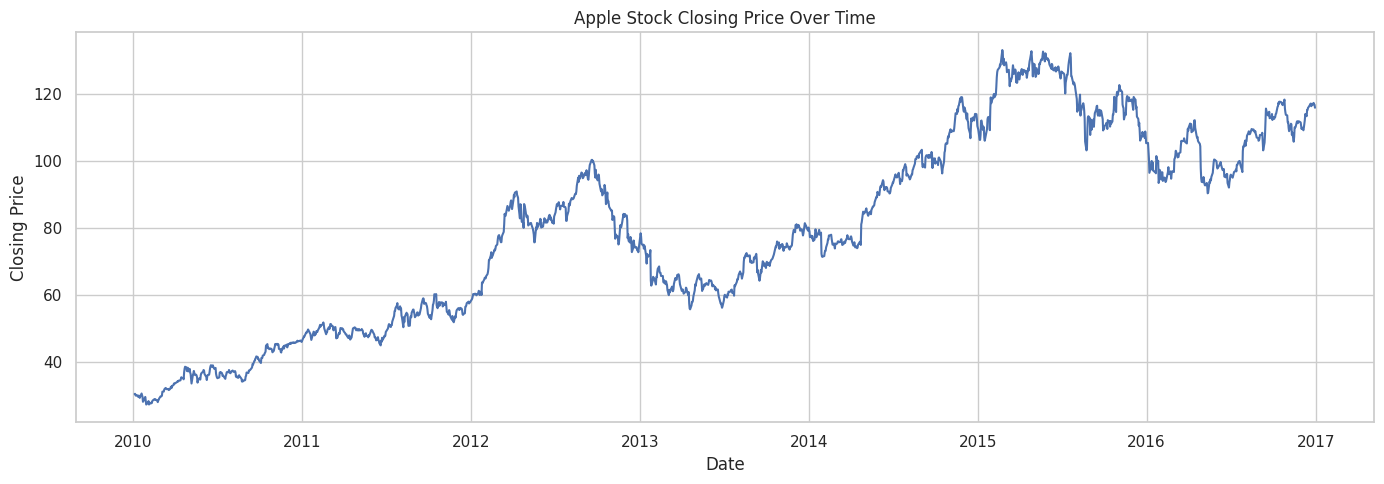

In [6]:

plt.figure(figsize=(14, 5))
plt.plot(apple["date"], apple["close"])
plt.title("Apple Stock Closing Price Over Time")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.tight_layout()
plt.show()


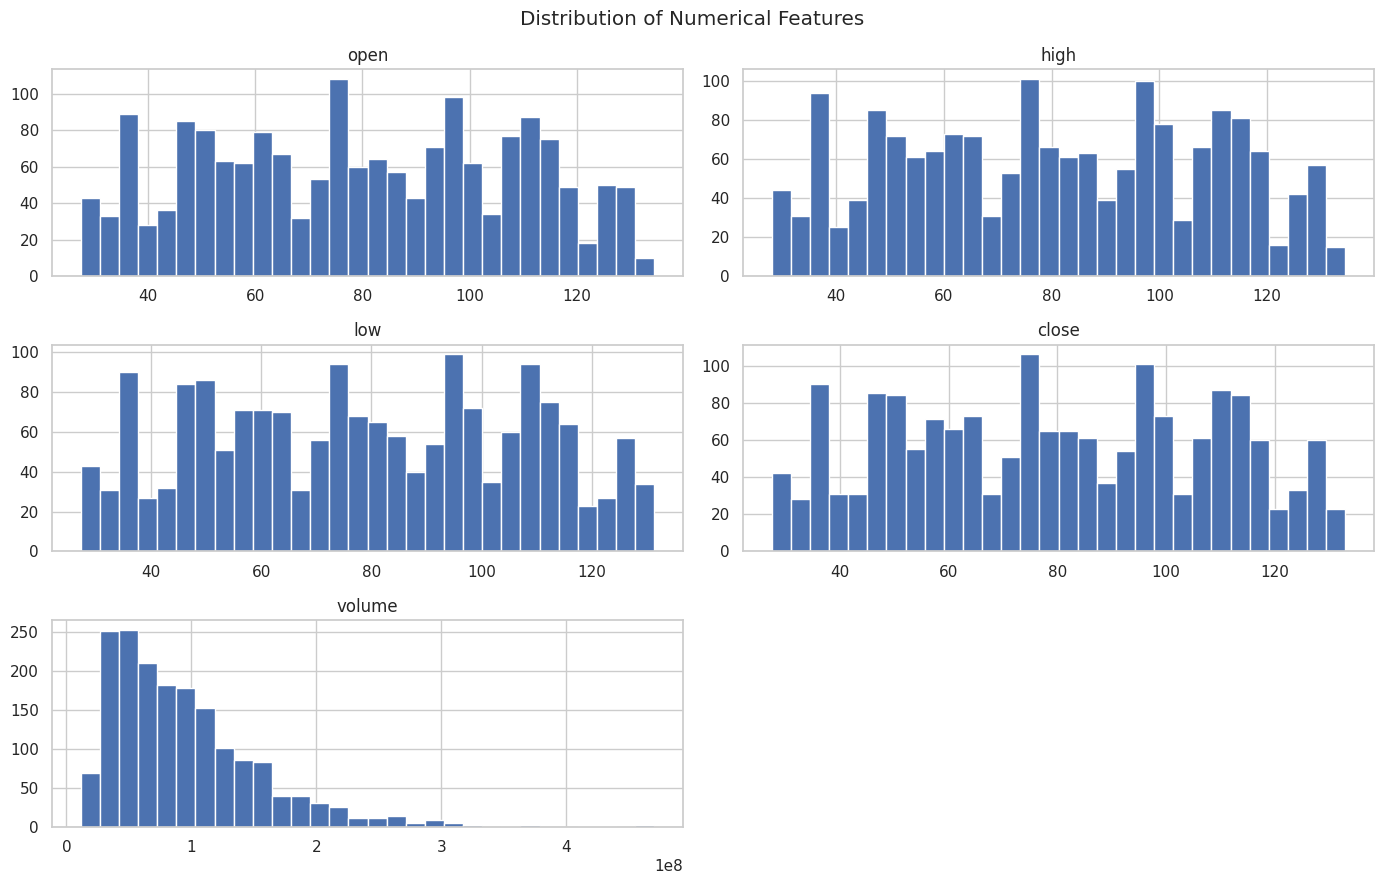

In [7]:

features = ["open", "high", "low", "close", "volume"]

apple[features].hist(figsize=(14, 9), bins=30)
plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()


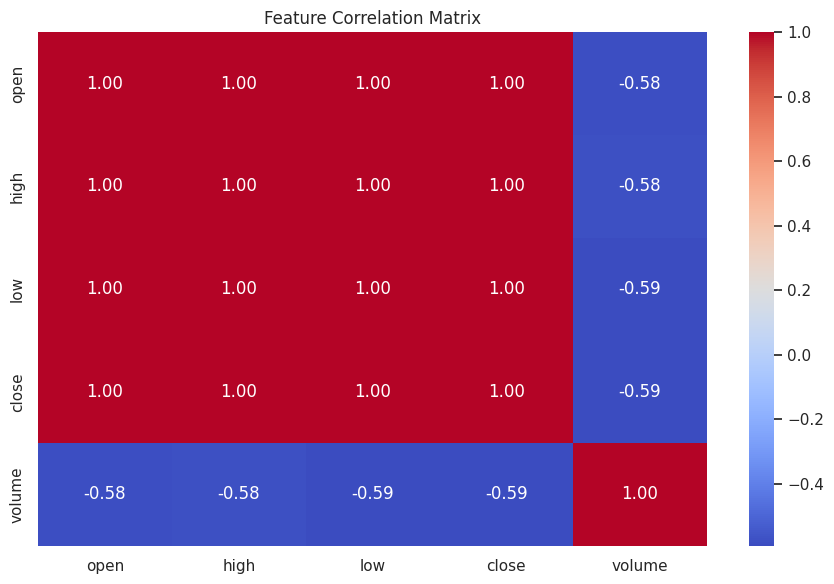

In [8]:

plt.figure(figsize=(9, 6))

sns.heatmap(
    apple[features].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()


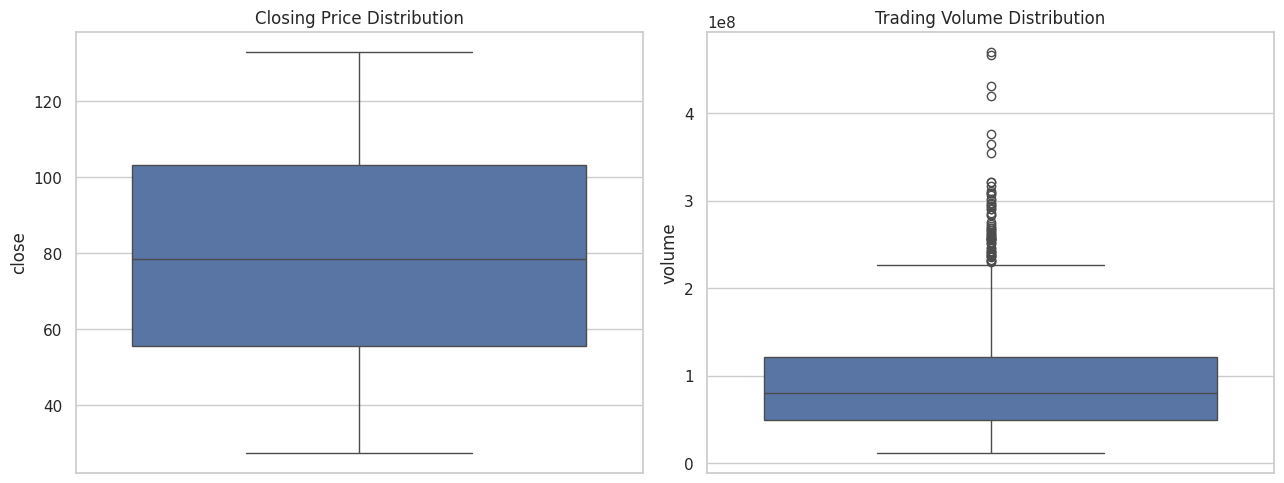

In [9]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(y=apple["close"], ax=axes[0])
axes[0].set_title("Closing Price Distribution")

sns.boxplot(y=apple["volume"], ax=axes[1])
axes[1].set_title("Trading Volume Distribution")

plt.tight_layout()
plt.show()


In [10]:

features = ["open", "high", "low", "close", "volume"]

data = apple.sort_values("date").copy()

data["next_close"] = data["close"].shift(-1)
data["target_date"] = data["date"].shift(-1)

data = data.dropna(
    subset=features + ["next_close", "target_date"]
).reset_index(drop=True)

X = data[features]
y = data[["next_close"]]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

display(data.head(10))


Features Shape: (1761, 5)
Target Shape: (1761, 1)


,date,symbol,open,close,low,high,volume,next_close,target_date
0,2010-01-04,AAPL,30.490000,30.572857,30.340000,30.642857,123432400.0,30.625713,2010-01-05
1,2010-01-05,AAPL,30.657143,30.625713,30.464285,30.798571,150476200.0,30.138571,2010-01-06
2,2010-01-06,AAPL,30.625713,30.138571,30.107143,30.747143,138040000.0,30.082857,2010-01-07
3,2010-01-07,AAPL,30.250000,30.082857,29.864286,30.285715,119282800.0,30.282858,2010-01-08
4,2010-01-08,AAPL,30.042856,30.282858,29.865715,30.285715,111902700.0,30.015715,2010-01-11
5,2010-01-11,AAPL,30.400000,30.015715,29.778572,30.428572,115557400.0,29.674286,2010-01-12
6,2010-01-12,AAPL,29.884285,29.674286,29.488571,29.967142,148614900.0,30.092857,2010-01-13
7,2010-01-13,AAPL,29.695715,30.092857,29.157143,30.132856,151473000.0,29.918571,2010-01-14
8,2010-01-14,AAPL,30.015715,29.918571,29.860001,30.065714,108223500.0,29.418571,2010-01-15
9,2010-01-15,AAPL,30.132856,29.418571,29.410000,30.228571,148516900.0,30.719999,2010-01-19


In [11]:

from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset

train_end = int(len(data) * 0.70)
val_end = int(len(data) * 0.85)

X_train = X.iloc[:train_end]
X_val = X.iloc[train_end:val_end]
X_test = X.iloc[val_end:]

y_train = y.iloc[:train_end]
y_val = y.iloc[train_end:val_end]
y_test = y.iloc[val_end:]

scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
X_val_scaled = scaler_X.transform(X_val)
X_test_scaled = scaler_X.transform(X_test)

y_train_scaled = scaler_y.fit_transform(y_train)
y_val_scaled = scaler_y.transform(y_val)
y_test_scaled = scaler_y.transform(y_test)

X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_scaled, dtype=torch.float32)

X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val_scaled, dtype=torch.float32)

X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)

train_loader = DataLoader(
    TensorDataset(X_train_tensor, y_train_tensor),
    batch_size=32,
    shuffle=True
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))
print("Device:", device)


Training: 1232
Validation: 264
Testing: 265
Device: cuda


In [12]:

import torch.nn as nn

class StockMLP(nn.Module):
    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.network(x)

model = StockMLP(input_size=X_train.shape[1]).to(device)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

print(model)


StockMLP(
  (network): Sequential(
    (0): Linear(in_features=5, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)


In [13]:

epochs = 120

train_losses = []
val_losses = []

for epoch in range(epochs):
    model.train()
    total_loss = 0

    for X_batch, y_batch in train_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        predictions = model(X_batch)

        loss = criterion(predictions, y_batch)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * X_batch.size(0)

    train_loss = total_loss / len(train_loader.dataset)

    model.eval()

    with torch.no_grad():
        val_predictions = model(X_val_tensor.to(device))
        val_loss = criterion(
            val_predictions,
            y_val_tensor.to(device)
        ).item()

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    if (epoch + 1) % 20 == 0:
        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Train Loss: {train_loss:.6f} "
            f"Val Loss: {val_loss:.6f}"
        )


Epoch [20/120] Train Loss: 0.003388 Val Loss: 0.011363
Epoch [40/120] Train Loss: 0.003293 Val Loss: 0.015438
Epoch [60/120] Train Loss: 0.003326 Val Loss: 0.010142
Epoch [80/120] Train Loss: 0.002976 Val Loss: 0.010709
Epoch [100/120] Train Loss: 0.002939 Val Loss: 0.015170
Epoch [120/120] Train Loss: 0.003112 Val Loss: 0.018213


Baseline MLP Results
MAE: 1.4628
MSE: 3.4766
RMSE: 1.8646
R2 Score: 0.9381


,Date,Actual Price,Predicted Price
0,2015-12-14,112.480003,114.833015
1,2015-12-15,110.489998,113.226654
2,2015-12-16,111.339996,111.901398
3,2015-12-17,108.980003,112.029633
4,2015-12-18,106.029999,110.260956
5,2015-12-21,107.330002,107.018806
6,2015-12-22,107.230003,107.904549
7,2015-12-23,108.610001,108.252625
8,2015-12-24,108.029999,109.540749
9,2015-12-28,106.820000,109.699715


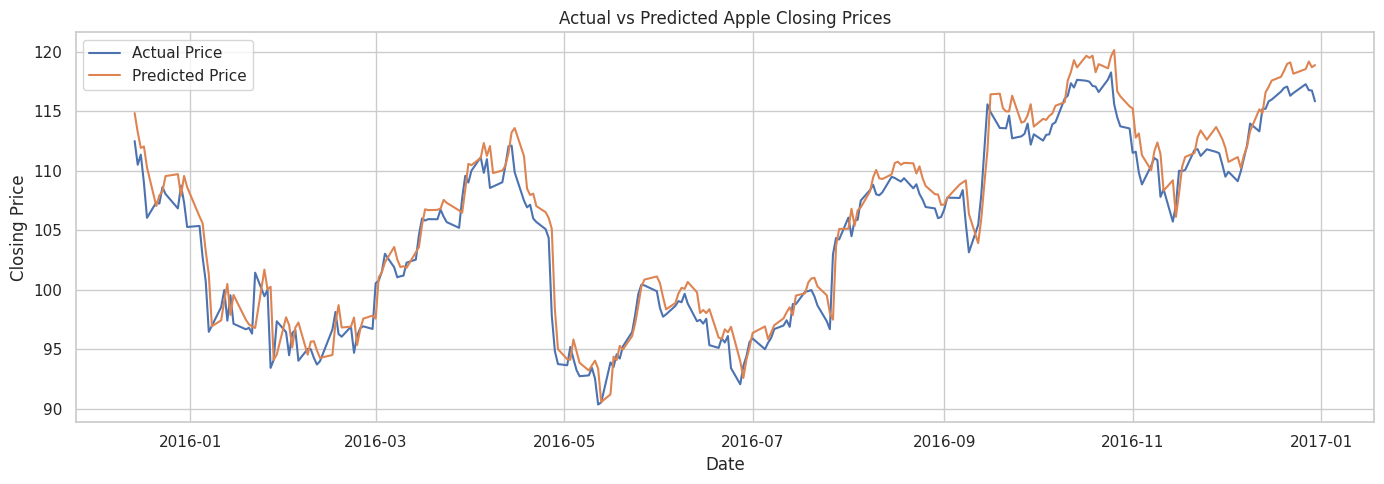

In [14]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

model.eval()

with torch.no_grad():
    predictions_scaled = model(
        X_test_tensor.to(device)
    ).cpu().numpy()

y_pred = scaler_y.inverse_transform(predictions_scaled).ravel()
y_true = y_test.to_numpy().ravel()

mae = mean_absolute_error(y_true, y_pred)
mse = mean_squared_error(y_true, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_true, y_pred)

print("Baseline MLP Results")
print(f"MAE: {mae:.4f}")
print(f"MSE: {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R2 Score: {r2:.4f}")

results = pd.DataFrame({
    "Date": data.iloc[val_end:]["target_date"].values,
    "Actual Price": y_true,
    "Predicted Price": y_pred
})

display(results.head(10))

plt.figure(figsize=(14, 5))

plt.plot(
    results["Date"],
    results["Actual Price"],
    label="Actual Price"
)

plt.plot(
    results["Date"],
    results["Predicted Price"],
    label="Predicted Price"
)

plt.title("Actual vs Predicted Apple Closing Prices")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.legend()
plt.tight_layout()
plt.show()


In [15]:

naive_pred = X_test["close"].to_numpy()
naive_true = y_test.to_numpy().ravel()

naive_mae = mean_absolute_error(naive_true, naive_pred)
naive_rmse = np.sqrt(mean_squared_error(naive_true, naive_pred))
naive_r2 = r2_score(naive_true, naive_pred)

comparison = pd.DataFrame({
    "Model": ["Naive Baseline", "MLP Baseline"],
    "MAE": [naive_mae, mae],
    "RMSE": [naive_rmse, rmse],
    "R2": [naive_r2, r2]
})

display(comparison)


,Model,MAE,RMSE,R2
0,Naive Baseline,1.063472,1.504279,0.959700
1,MLP Baseline,1.462758,1.864577,0.938083


In [18]:

from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

class TorchRegressor(RegressorMixin, BaseEstimator):
    def __init__(
        self,
        hidden_layers=(64, 32),
        optimizer_name="adam",
        learning_rate=0.001,
        epochs=50,
        batch_size=64
    ):
        self.hidden_layers = hidden_layers
        self.optimizer_name = optimizer_name
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.batch_size = batch_size

    def fit(self, X, y):
        torch.manual_seed(42)

        X_arr = np.asarray(X, dtype=np.float32)
        y_arr = np.asarray(y, dtype=np.float32).reshape(-1, 1)

        self.target_mean_ = float(y_arr.mean())
        self.target_std_ = max(float(y_arr.std()), 1e-8)

        y_scaled = (y_arr - self.target_mean_) / self.target_std_

        layers = []
        input_dim = X_arr.shape[1]

        for units in self.hidden_layers:
            layers.append(nn.Linear(input_dim, units))
            layers.append(nn.ReLU())
            input_dim = units

        layers.append(nn.Linear(input_dim, 1))

        self.model_ = nn.Sequential(*layers)

        optimizers = {
            "adam": torch.optim.Adam,
            "rmsprop": torch.optim.RMSprop
        }

        optimizer = optimizers[self.optimizer_name](
            self.model_.parameters(),
            lr=self.learning_rate
        )

        loader = DataLoader(
            TensorDataset(
                torch.from_numpy(X_arr),
                torch.from_numpy(y_scaled)
            ),
            batch_size=self.batch_size,
            shuffle=True
        )

        self.model_.train()

        for epoch in range(self.epochs):
            for xb, yb in loader:
                optimizer.zero_grad()
                loss = nn.functional.mse_loss(self.model_(xb), yb)
                loss.backward()
                optimizer.step()

        return self

    def predict(self, X):
        X_arr = np.asarray(X, dtype=np.float32)
        self.model_.eval()

        with torch.no_grad():
            pred = self.model_(
                torch.from_numpy(X_arr)
            ).numpy().ravel()

        return pred * self.target_std_ + self.target_mean_


In [19]:

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", TorchRegressor())
])

param_grid = {
    "regressor__hidden_layers": [(32, 16), (64, 32)],
    "regressor__optimizer_name": ["adam", "rmsprop"],
    "regressor__learning_rate": [0.001, 0.003],
    "regressor__epochs": [30, 60]
}

grid = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=TimeSeriesSplit(n_splits=3),
    scoring="neg_mean_squared_error",
    n_jobs=1,
    verbose=1,
    refit=True
)

grid.fit(X_train, y_train.to_numpy().ravel())

print("Best Parameters:")
print(grid.best_params_)

print("\nCross-Validation RMSE:")
print(np.sqrt(-grid.best_score_))


Fitting 3 folds for each of 16 candidates, totalling 48 fits
Best Parameters:
{'regressor__epochs': 30, 'regressor__hidden_layers': (32, 16), 'regressor__learning_rate': 0.003, 'regressor__optimizer_name': 'adam'}

Cross-Validation RMSE:
1.4247769410881697


,Model,MAE,RMSE,R2
0,Naive Baseline,1.0635,1.5043,0.9597
1,MLP Baseline,1.4628,1.8646,0.9381
2,Optimized MLP,1.1309,1.5880,0.9551


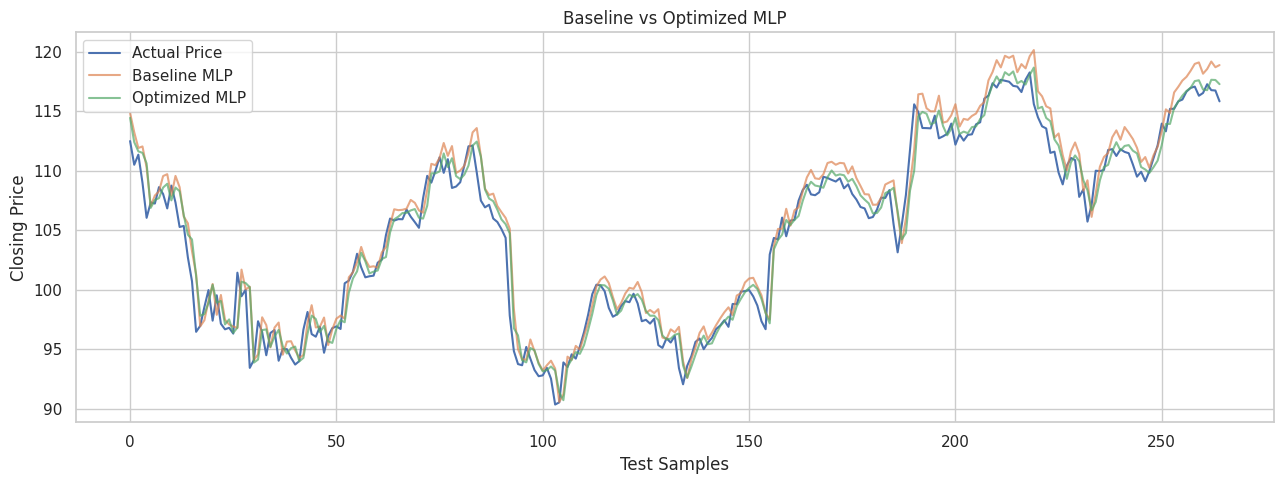

In [20]:

optimized_pred = grid.predict(X_test)

optimized_mae = mean_absolute_error(y_true, optimized_pred)
optimized_rmse = np.sqrt(mean_squared_error(y_true, optimized_pred))
optimized_r2 = r2_score(y_true, optimized_pred)

comparison = pd.DataFrame({
    "Model": ["Naive Baseline", "MLP Baseline", "Optimized MLP"],
    "MAE": [naive_mae, mae, optimized_mae],
    "RMSE": [naive_rmse, rmse, optimized_rmse],
    "R2": [naive_r2, r2, optimized_r2]
})

display(comparison.round(4))

plt.figure(figsize=(13, 5))
plt.plot(y_true, label="Actual Price")
plt.plot(y_pred, label="Baseline MLP", alpha=0.7)
plt.plot(optimized_pred, label="Optimized MLP", alpha=0.7)
plt.title("Baseline vs Optimized MLP")
plt.xlabel("Test Samples")
plt.ylabel("Closing Price")
plt.legend()
plt.tight_layout()
plt.show()


In [21]:

torch.manual_seed(42)

best_params = grid.best_params_
hidden_sizes = best_params["regressor__hidden_layers"]
best_epochs = best_params["regressor__epochs"]
best_lr = best_params["regressor__learning_rate"]
best_optimizer = best_params["regressor__optimizer_name"]

layers = []
input_dim = X_train.shape[1]

for units in hidden_sizes:
    layers.extend([nn.Linear(input_dim, units), nn.ReLU()])
    input_dim = units

layers.append(nn.Linear(input_dim, 1))

curve_model = nn.Sequential(*layers).to(device)

optimizer_classes = {
    "adam": torch.optim.Adam,
    "rmsprop": torch.optim.RMSprop
}

curve_optimizer = optimizer_classes[best_optimizer](
    curve_model.parameters(),
    lr=best_lr
)

curve_loader = DataLoader(
    TensorDataset(X_train_tensor, y_train_tensor),
    batch_size=64,
    shuffle=True
)

y_test_tensor = torch.tensor(y_test_scaled, dtype=torch.float32)

train_loss_history = []
test_loss_history = []
train_accuracy_history = []
test_accuracy_history = []

price_mean = float(scaler_y.mean_[0])
price_std = float(scaler_y.scale_[0])

for epoch in range(best_epochs):
    curve_model.train()

    for xb, yb in curve_loader:
        xb = xb.to(device)
        yb = yb.to(device)

        curve_optimizer.zero_grad()
        prediction = curve_model(xb)
        loss = nn.functional.mse_loss(prediction, yb)
        loss.backward()
        curve_optimizer.step()

    curve_model.eval()

    with torch.no_grad():
        train_pred = curve_model(X_train_tensor.to(device))
        test_pred = curve_model(X_test_tensor.to(device))

        train_true = y_train_tensor.to(device)
        test_true = y_test_tensor.to(device)

        train_loss_history.append(
            nn.functional.mse_loss(train_pred, train_true).item()
        )

        test_loss_history.append(
            nn.functional.mse_loss(test_pred, test_true).item()
        )

        train_pred_real = train_pred * price_std + price_mean
        test_pred_real = test_pred * price_std + price_mean
        train_true_real = train_true * price_std + price_mean
        test_true_real = test_true * price_std + price_mean

        train_acc = (
            (torch.abs(train_pred_real - train_true_real)
             <= 0.05 * torch.abs(train_true_real)).float().mean().item() * 100
        )

        test_acc = (
            (torch.abs(test_pred_real - test_true_real)
             <= 0.05 * torch.abs(test_true_real)).float().mean().item() * 100
        )

        train_accuracy_history.append(train_acc)
        test_accuracy_history.append(test_acc)

    if (epoch + 1) % 5 == 0:
        print(
            f"Epoch {epoch+1}/{best_epochs} | "
            f"Train Loss: {train_loss_history[-1]:.5f} | "
            f"Test Loss: {test_loss_history[-1]:.5f} | "
            f"Train Acc@5%: {train_acc:.2f}% | "
            f"Test Acc@5%: {test_acc:.2f}%"
        )


Epoch 5/30 | Train Loss: 0.00416 | Test Loss: 0.00565 | Train Acc@5%: 97.81% | Test Acc@5%: 98.49%
Epoch 10/30 | Train Loss: 0.00342 | Test Loss: 0.00548 | Train Acc@5%: 98.78% | Test Acc@5%: 98.49%
Epoch 15/30 | Train Loss: 0.00327 | Test Loss: 0.00550 | Train Acc@5%: 98.62% | Test Acc@5%: 98.49%
Epoch 20/30 | Train Loss: 0.00324 | Test Loss: 0.00561 | Train Acc@5%: 98.62% | Test Acc@5%: 98.87%
Epoch 25/30 | Train Loss: 0.00318 | Test Loss: 0.00615 | Train Acc@5%: 98.46% | Test Acc@5%: 98.87%
Epoch 30/30 | Train Loss: 0.00313 | Test Loss: 0.00585 | Train Acc@5%: 98.70% | Test Acc@5%: 98.87%


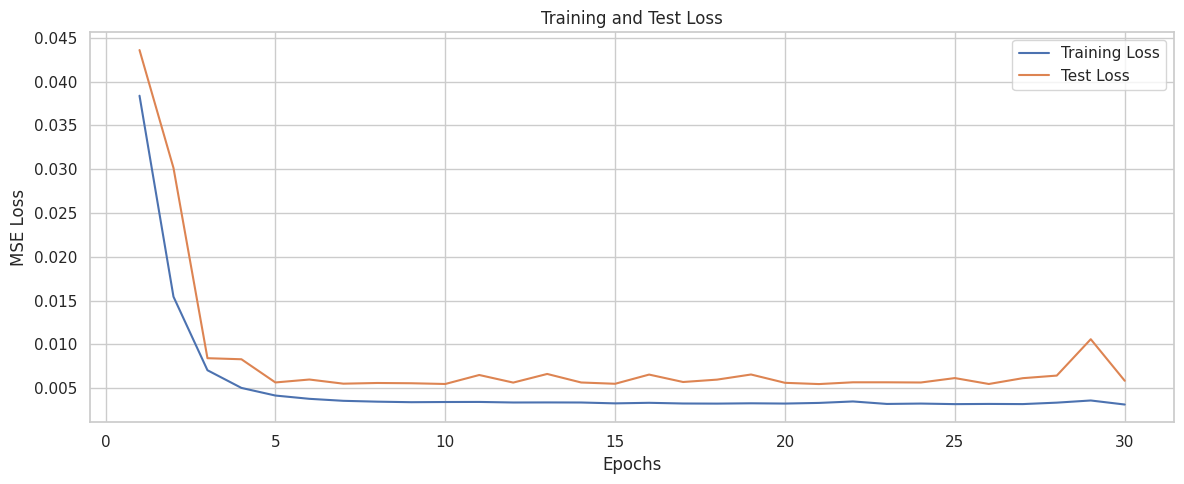

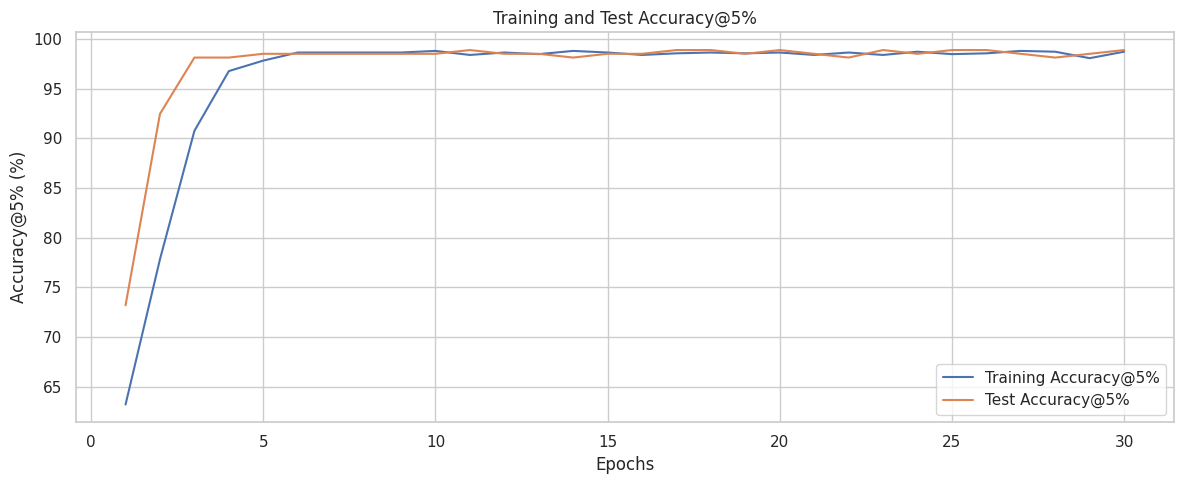

In [22]:

epoch_range = range(1, best_epochs + 1)

plt.figure(figsize=(12, 5))
plt.plot(epoch_range, train_loss_history, label="Training Loss")
plt.plot(epoch_range, test_loss_history, label="Test Loss")
plt.xlabel("Epochs")
plt.ylabel("MSE Loss")
plt.title("Training and Test Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 5))
plt.plot(epoch_range, train_accuracy_history, label="Training Accuracy@5%")
plt.plot(epoch_range, test_accuracy_history, label="Test Accuracy@5%")
plt.xlabel("Epochs")
plt.ylabel("Accuracy@5% (%)")
plt.title("Training and Test Accuracy@5%")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [23]:

import copy

class RegularizedMLP(nn.Module):
    def __init__(self, hidden_layers=(32, 16), dropout=0.0):
        super().__init__()

        layers = []
        input_dim = X_train.shape[1]

        for units in hidden_layers:
            layers.append(nn.Linear(input_dim, units))
            layers.append(nn.ReLU())

            if dropout > 0:
                layers.append(nn.Dropout(dropout))

            input_dim = units

        layers.append(nn.Linear(input_dim, 1))

        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)


In [24]:

def train_regularized_model(name, dropout=0.0, weight_decay=0.0, early_stopping=False):
    torch.manual_seed(42)

    net = RegularizedMLP(
        hidden_layers=best_params["regressor__hidden_layers"],
        dropout=dropout
    ).to(device)

    optimizer_class = {
        "adam": torch.optim.Adam,
        "rmsprop": torch.optim.RMSprop
    }[best_params["regressor__optimizer_name"]]

    opt = optimizer_class(
        net.parameters(),
        lr=best_params["regressor__learning_rate"],
        weight_decay=weight_decay
    )

    loader = DataLoader(
        TensorDataset(X_train_tensor, y_train_tensor),
        batch_size=64,
        shuffle=True,
        generator=torch.Generator().manual_seed(42)
    )

    max_epochs = 120 if early_stopping else best_params["regressor__epochs"]

    train_history = []
    val_history = []

    best_val = float("inf")
    best_state = None
    best_epoch = 0
    patience = 12
    waiting = 0

    for epoch in range(max_epochs):
        net.train()

        for xb, yb in loader:
            xb = xb.to(device)
            yb = yb.to(device)

            opt.zero_grad()
            output = net(xb)
            loss = nn.functional.mse_loss(output, yb)
            loss.backward()
            opt.step()

        net.eval()

        with torch.no_grad():
            train_output = net(X_train_tensor.to(device))
            val_output = net(X_val_tensor.to(device))

            train_loss = nn.functional.mse_loss(
                train_output, y_train_tensor.to(device)
            ).item()

            val_loss = nn.functional.mse_loss(
                val_output, y_val_tensor.to(device)
            ).item()

        train_history.append(train_loss)
        val_history.append(val_loss)

        if val_loss < best_val - 1e-5:
            best_val = val_loss
            best_epoch = epoch + 1
            best_state = copy.deepcopy(net.state_dict())
            waiting = 0
        else:
            waiting += 1

        if early_stopping and waiting >= patience:
            break

    if early_stopping:
        net.load_state_dict(best_state)

    print(f"{name}: {len(train_history)} epochs completed")

    return {
        "name": name,
        "network": net,
        "train_loss": train_history,
        "val_loss": val_history,
        "best_epoch": best_epoch
    }


In [25]:

configurations = [
    {
        "name": "Dropout",
        "dropout": 0.1,
        "weight_decay": 0.0,
        "early_stopping": False
    },
    {
        "name": "L2 Weight Decay",
        "dropout": 0.0,
        "weight_decay": 0.0001,
        "early_stopping": False
    },
    {
        "name": "Dropout + L2 + Early Stopping",
        "dropout": 0.1,
        "weight_decay": 0.0001,
        "early_stopping": True
    }
]

regularized_models = []

for config in configurations:
    result = train_regularized_model(**config)
    regularized_models.append(result)

print("Regularization Experiments Completed")


Dropout: 30 epochs completed
L2 Weight Decay: 30 epochs completed
Dropout + L2 + Early Stopping: 23 epochs completed
Regularization Experiments Completed


In [27]:

def calculate_metrics(name, val_pred, test_pred):
    return {
        "Model": name,
        "Validation RMSE": np.sqrt(
            mean_squared_error(y_val.to_numpy().ravel(), val_pred)
        ),
        "Test MAE": mean_absolute_error(y_true, test_pred),
        "Test RMSE": np.sqrt(mean_squared_error(y_true, test_pred)),
        "Test R2": r2_score(y_true, test_pred)
    }

model.eval()

with torch.no_grad():
    baseline_val_scaled = model(
        X_val_tensor.to(device)
    ).cpu().numpy()

baseline_val_pred = scaler_y.inverse_transform(
    baseline_val_scaled
).ravel()

comparison_rows = [
    calculate_metrics(
        "Naive Baseline",
        X_val["close"].to_numpy(),
        X_test["close"].to_numpy()
    ),
    calculate_metrics(
        "MLP Baseline",
        baseline_val_pred,
        y_pred
    ),
    calculate_metrics(
        "Optimized MLP",
        grid.predict(X_val),
        optimized_pred
    )
]

for result in regularized_models:
    net = result["network"]
    net.eval()

    with torch.no_grad():
        val_scaled = net(X_val_tensor.to(device)).cpu().numpy()
        test_scaled = net(X_test_tensor.to(device)).cpu().numpy()

    val_pred = scaler_y.inverse_transform(val_scaled).ravel()
    test_pred = scaler_y.inverse_transform(test_scaled).ravel()

    result["test_predictions"] = test_pred

    comparison_rows.append(
        calculate_metrics(result["name"], val_pred, test_pred)
    )

regularization_comparison = pd.DataFrame(comparison_rows)

display(
    regularization_comparison
    .sort_values("Validation RMSE")
    .round(4)
)


,Model,Validation RMSE,Test MAE,Test RMSE,Test R2
0,Naive Baseline,1.9566,1.0635,1.5043,0.9597
5,Dropout + L2 + Early Stopping,2.0963,1.1662,1.6161,0.9535
2,Optimized MLP,2.0966,1.1309,1.5880,0.9551
4,L2 Weight Decay,2.1506,1.2537,1.6636,0.9507
3,Dropout,2.7572,1.5172,1.9099,0.9350
1,MLP Baseline,2.8027,1.4628,1.8646,0.9381


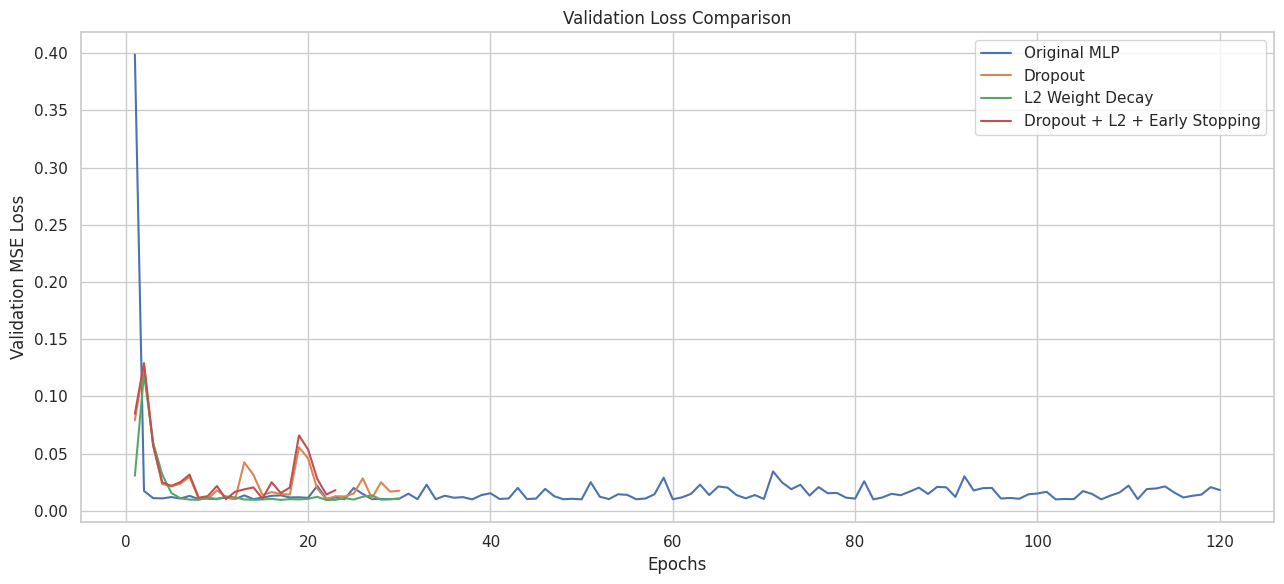

Dropout | Best Epoch: 22 | Best Validation Loss: 0.010077
L2 Weight Decay | Best Epoch: 22 | Best Validation Loss: 0.009515
Dropout + L2 + Early Stopping | Best Epoch: 11 | Best Validation Loss: 0.010189


In [28]:

plt.figure(figsize=(13, 6))

plt.plot(
    range(1, len(val_losses) + 1),
    val_losses,
    label="Original MLP"
)

for result in regularized_models:
    plt.plot(
        range(1, len(result["val_loss"]) + 1),
        result["val_loss"],
        label=result["name"]
    )

plt.title("Validation Loss Comparison")
plt.xlabel("Epochs")
plt.ylabel("Validation MSE Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

for result in regularized_models:
    print(
        f"{result['name']} | "
        f"Best Epoch: {result['best_epoch']} | "
        f"Best Validation Loss: {min(result['val_loss']):.6f}"
    )


In [29]:

from pathlib import Path
import pandas as pd
import numpy as np

files = list(Path("/kaggle/input").rglob("predictive_maintenance.csv"))

if not files:
    raise FileNotFoundError("predictive_maintenance.csv not found")

maintenance = pd.read_csv(files[0])

print("Dataset Shape:", maintenance.shape)
print("Columns:", maintenance.columns.tolist())

display(maintenance.head(10))


Dataset Shape: (10000, 10)
Columns: ['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Target', 'Failure Type']


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,No Failure
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,No Failure
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,No Failure
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,No Failure
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,No Failure
5,6,M14865,M,298.1,308.6,1425,41.9,11,0,No Failure
6,7,L47186,L,298.1,308.6,1558,42.4,14,0,No Failure
7,8,L47187,L,298.1,308.6,1527,40.2,16,0,No Failure
8,9,M14868,M,298.3,308.7,1667,28.6,18,0,No Failure
9,10,M14869,M,298.5,309.0,1741,28.0,21,0,No Failure


In [30]:

print("Dataset Information:")
maintenance.info()

print("\nMissing Values:")
display(
    maintenance.isnull().sum().to_frame("Missing Values")
)

print("\nDuplicate Rows:", maintenance.duplicated().sum())

print("\nStatistical Summary:")
display(maintenance.describe(include="all").T)

print("\nTarget Distribution:")
display(
    maintenance["Failure Type"].value_counts().to_frame("Count")
)


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Target                   10000 non-null  int64  
 9   Failure Type             10000 non-null  object 
dtypes: float64(3), int64(4), object(3)
memory usage: 781.4+ KB

Missing Values:


,Missing Values
UDI,0
Product ID,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Target,0
Failure Type,0



Duplicate Rows: 0

Statistical Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
UDI,10000.0,NaN,NaN,NaN,5000.5,2886.89568,1.0,2500.75,5000.5,7500.25,10000.0
Product ID,10000,10000,M24859,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Type,10000,3,L,6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Air temperature [K],10000.0,NaN,NaN,NaN,300.00493,2.000259,295.3,298.3,300.1,301.5,304.5
Process temperature [K],10000.0,NaN,NaN,NaN,310.00556,1.483734,305.7,308.8,310.1,311.1,313.8
Rotational speed [rpm],10000.0,NaN,NaN,NaN,1538.7761,179.284096,1168.0,1423.0,1503.0,1612.0,2886.0
Torque [Nm],10000.0,NaN,NaN,NaN,39.98691,9.968934,3.8,33.2,40.1,46.8,76.6
Tool wear [min],10000.0,NaN,NaN,NaN,107.951,63.654147,0.0,53.0,108.0,162.0,253.0
Target,10000.0,NaN,NaN,NaN,0.0339,0.180981,0.0,0.0,0.0,0.0,1.0
Failure Type,10000,6,No Failure,9652,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Target Distribution:


,Count
Failure Type,
No Failure,9652
Heat Dissipation Failure,112
Power Failure,95
Overstrain Failure,78
Tool Wear Failure,45
Random Failures,18


In [31]:

from sklearn.preprocessing import LabelEncoder

maintenance_clean = maintenance.drop_duplicates().copy()

maintenance_clean = maintenance_clean.dropna(
    subset=["Failure Type"]
)

label_encoder = LabelEncoder()

maintenance_clean["Failure_Type_Encoded"] = (
    label_encoder.fit_transform(
        maintenance_clean["Failure Type"]
    )
)

columns_to_drop = [
    "UDI",
    "Product ID",
    "Target",
    "Failure Type",
    "Failure_Type_Encoded"
]

X_cls = maintenance_clean.drop(
    columns=columns_to_drop
)

y_cls = maintenance_clean["Failure_Type_Encoded"]

print("Features Shape:", X_cls.shape)
print("Target Shape:", y_cls.shape)

print("\nClass Encoding:")
for i, label in enumerate(label_encoder.classes_):
    print(f"{i}: {label}")

display(X_cls.head())


Features Shape: (10000, 6)
Target Shape: (10000,)

Class Encoding:
0: Heat Dissipation Failure
1: No Failure
2: Overstrain Failure
3: Power Failure
4: Random Failures
5: Tool Wear Failure


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
0,M,298.1,308.6,1551,42.8,0
1,L,298.2,308.7,1408,46.3,3
2,L,298.1,308.5,1498,49.4,5
3,L,298.2,308.6,1433,39.5,7
4,L,298.2,308.7,1408,40.0,9


In [32]:

from sklearn.model_selection import train_test_split

X_cls_train, X_cls_temp, y_cls_train, y_cls_temp = train_test_split(
    X_cls,
    y_cls,
    test_size=0.30,
    random_state=42,
    stratify=y_cls
)

X_cls_val, X_cls_test, y_cls_val, y_cls_test = train_test_split(
    X_cls_temp,
    y_cls_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_cls_temp
)

print("Training Samples:", len(X_cls_train))
print("Validation Samples:", len(X_cls_val))
print("Testing Samples:", len(X_cls_test))


Training Samples: 7000
Validation Samples: 1500
Testing Samples: 1500


In [33]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

numeric_columns = X_cls_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_columns = X_cls_train.select_dtypes(
    exclude=np.number
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_columns),
    ("categorical", categorical_pipeline, categorical_columns)
])

X_cls_train_processed = preprocessor.fit_transform(X_cls_train)
X_cls_val_processed = preprocessor.transform(X_cls_val)
X_cls_test_processed = preprocessor.transform(X_cls_test)

X_cls_train_processed = np.asarray(
    X_cls_train_processed, dtype=np.float32
)

X_cls_val_processed = np.asarray(
    X_cls_val_processed, dtype=np.float32
)

X_cls_test_processed = np.asarray(
    X_cls_test_processed, dtype=np.float32
)

print("Processed Training Shape:", X_cls_train_processed.shape)
print("Processed Validation Shape:", X_cls_val_processed.shape)
print("Processed Test Shape:", X_cls_test_processed.shape)

print("\nProcessed Features:")
print(preprocessor.get_feature_names_out())


Processed Training Shape: (7000, 8)
Processed Validation Shape: (1500, 8)
Processed Test Shape: (1500, 8)

Processed Features:
['numeric__Air temperature [K]' 'numeric__Process temperature [K]'
 'numeric__Rotational speed [rpm]' 'numeric__Torque [Nm]'
 'numeric__Tool wear [min]' 'categorical__Type_H' 'categorical__Type_L'
 'categorical__Type_M']


In [34]:

y_cls_train_np = y_cls_train.to_numpy(dtype=np.int64)
y_cls_val_np = y_cls_val.to_numpy(dtype=np.int64)
y_cls_test_np = y_cls_test.to_numpy(dtype=np.int64)

print("Training Shape:", X_cls_train_processed.shape)
print("Validation Shape:", X_cls_val_processed.shape)
print("Testing Shape:", X_cls_test_processed.shape)

print("\nMissing Values After Preprocessing:")
print("Train:", np.isnan(X_cls_train_processed).sum())
print("Validation:", np.isnan(X_cls_val_processed).sum())
print("Test:", np.isnan(X_cls_test_processed).sum())

print("\nClass Distribution:")

class_distribution = pd.DataFrame({
    "Class": label_encoder.classes_,
    "Training": np.bincount(
        y_cls_train_np, minlength=len(label_encoder.classes_)
    ),
    "Validation": np.bincount(
        y_cls_val_np, minlength=len(label_encoder.classes_)
    ),
    "Testing": np.bincount(
        y_cls_test_np, minlength=len(label_encoder.classes_)
    )
})

display(class_distribution)

print("\nPreprocessing Completed Successfully")


Training Shape: (7000, 8)
Validation Shape: (1500, 8)
Testing Shape: (1500, 8)

Missing Values After Preprocessing:
Train: 0
Validation: 0
Test: 0

Class Distribution:


,Class,Training,Validation,Testing
0,Heat Dissipation Failure,78,17,17
1,No Failure,6756,1448,1448
2,Overstrain Failure,55,11,12
3,Power Failure,67,14,14
4,Random Failures,13,3,2
5,Tool Wear Failure,31,7,7



Preprocessing Completed Successfully


In [35]:

numeric_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

class_counts = maintenance_clean["Failure Type"].value_counts()

class_distribution = pd.DataFrame({
    "Count": class_counts,
    "Percentage (%)": class_counts / len(maintenance_clean) * 100
})

display(class_distribution.round(2))

print("Total Samples:", len(maintenance_clean))
print("Number of Classes:", len(class_counts))
print("Imbalance Ratio:", round(class_counts.max() / class_counts.min(), 2))


,Count,Percentage (%)
Failure Type,,
No Failure,9652,96.52
Heat Dissipation Failure,112,1.12
Power Failure,95,0.95
Overstrain Failure,78,0.78
Tool Wear Failure,45,0.45
Random Failures,18,0.18


Total Samples: 10000
Number of Classes: 6
Imbalance Ratio: 536.22


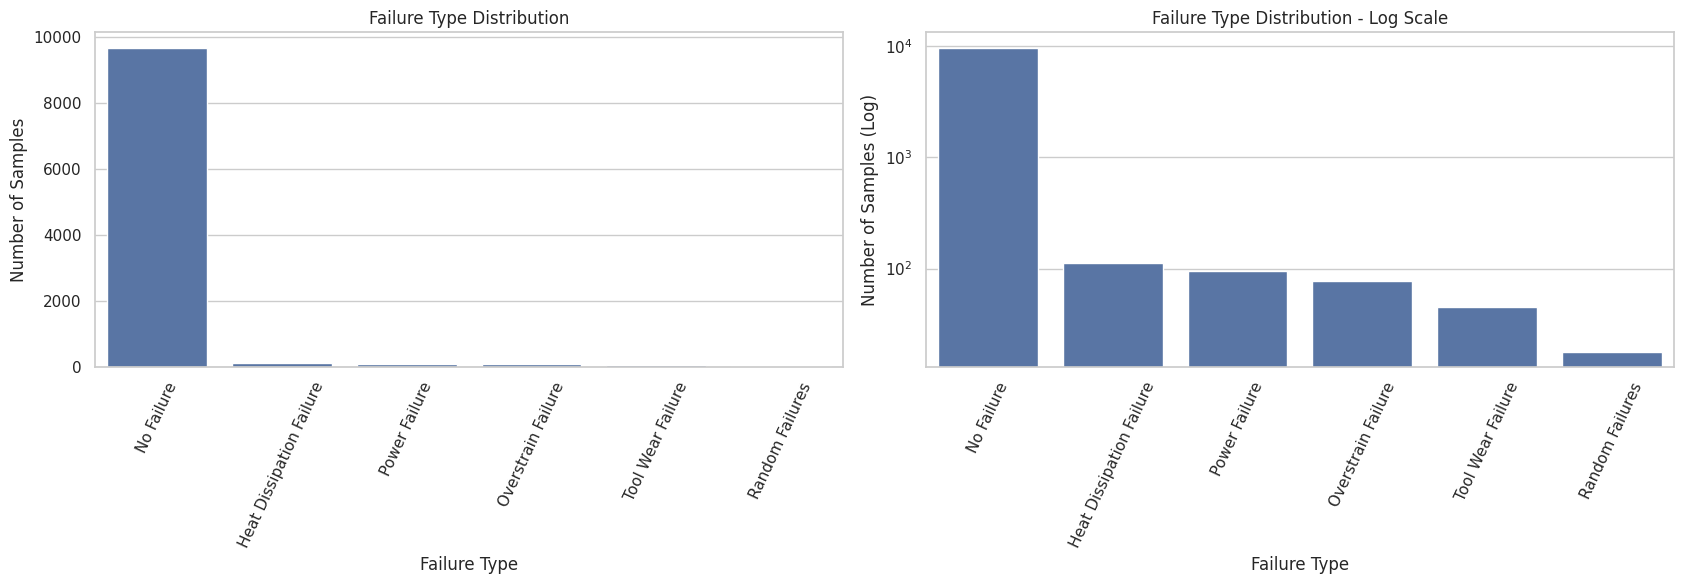

In [36]:

fig, axes = plt.subplots(1, 2, figsize=(17, 6))

sns.barplot(
    x=class_counts.index,
    y=class_counts.values,
    ax=axes[0]
)

axes[0].set_title("Failure Type Distribution")
axes[0].set_xlabel("Failure Type")
axes[0].set_ylabel("Number of Samples")
axes[0].tick_params(axis="x", rotation=65)

sns.barplot(
    x=class_counts.index,
    y=class_counts.values,
    ax=axes[1]
)

axes[1].set_yscale("log")
axes[1].set_title("Failure Type Distribution - Log Scale")
axes[1].set_xlabel("Failure Type")
axes[1].set_ylabel("Number of Samples (Log)")
axes[1].tick_params(axis="x", rotation=65)

plt.tight_layout()
plt.show()


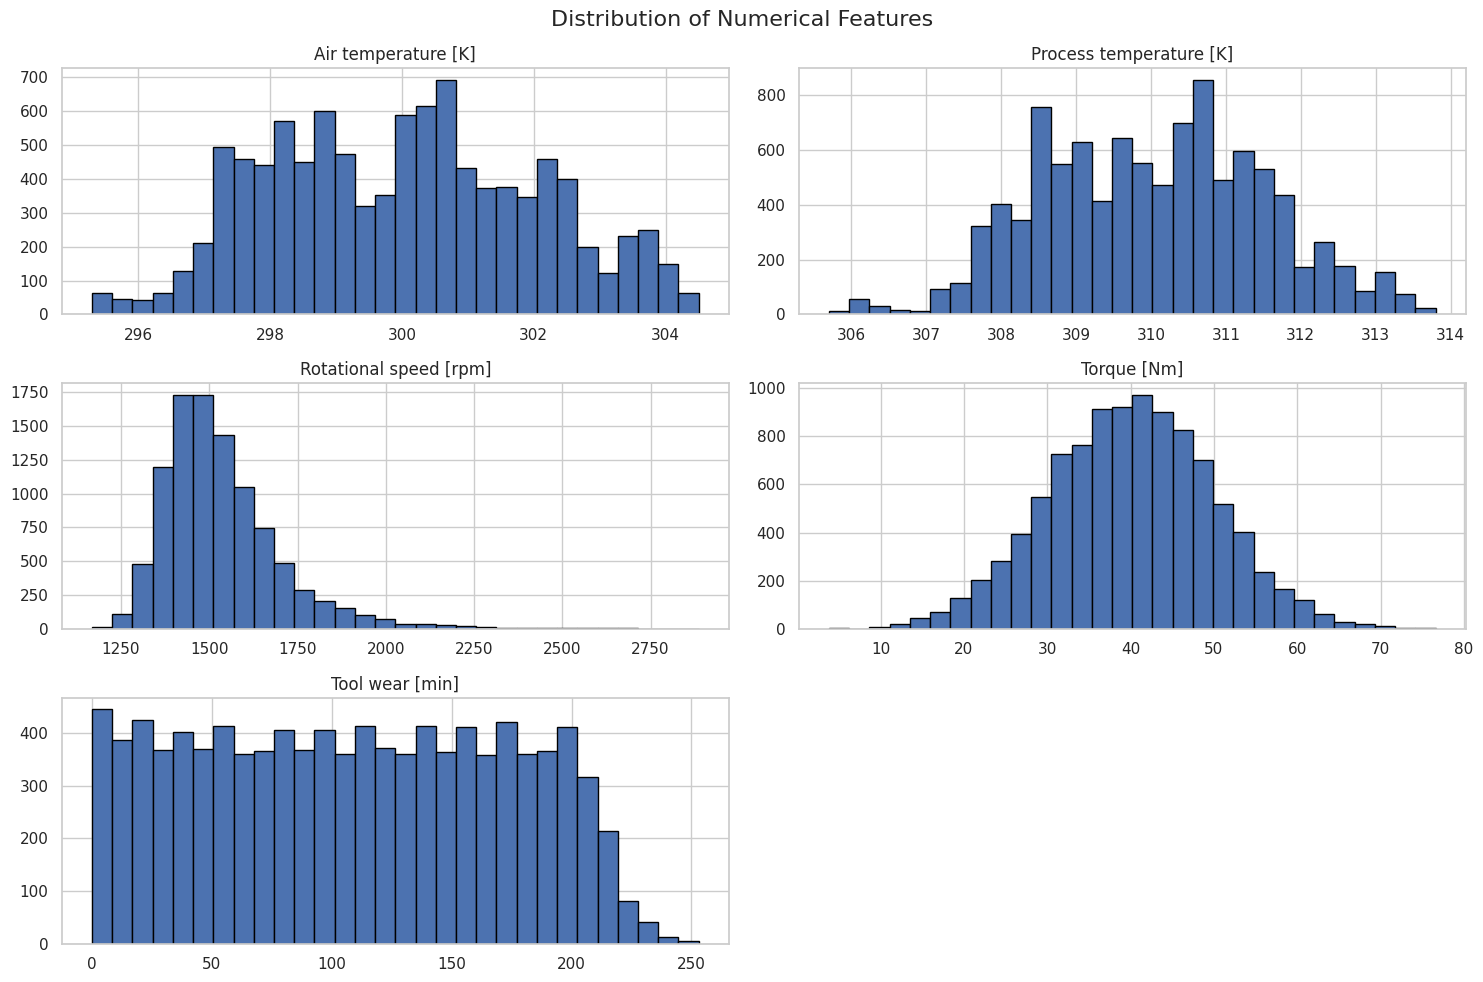

In [37]:

maintenance_clean[numeric_features].hist(
    figsize=(15, 10),
    bins=30,
    edgecolor="black"
)

plt.suptitle(
    "Distribution of Numerical Features",
    fontsize=16
)

plt.tight_layout()
plt.show()


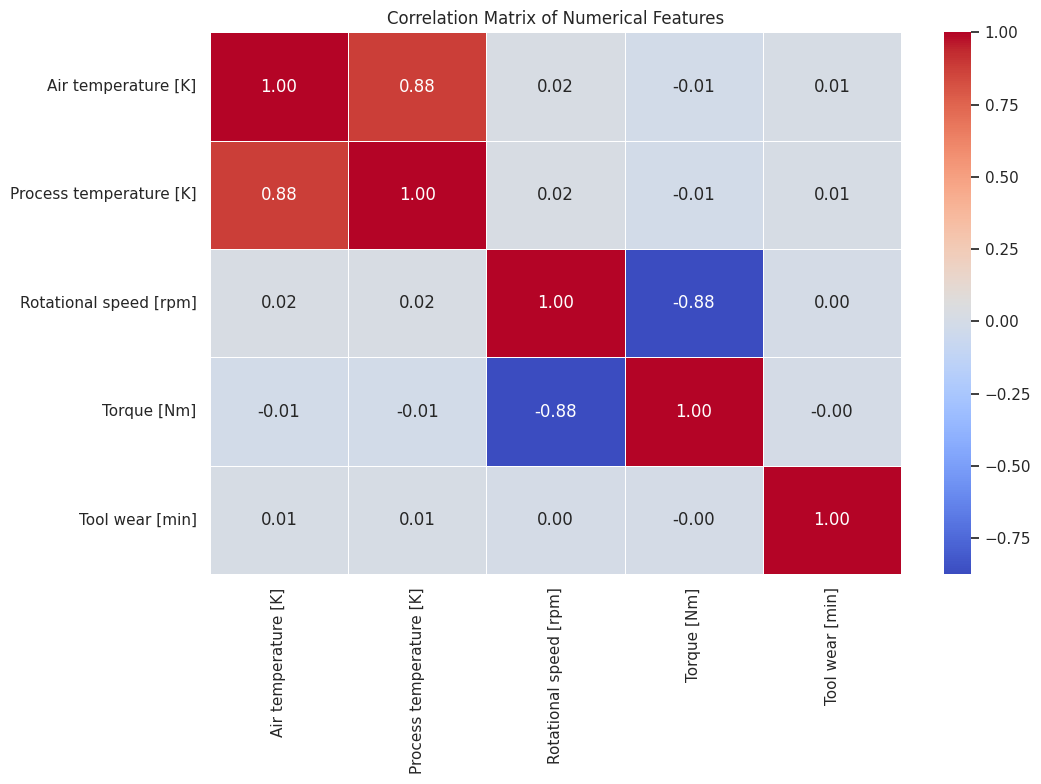

In [38]:

correlation_matrix = maintenance_clean[numeric_features].corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()


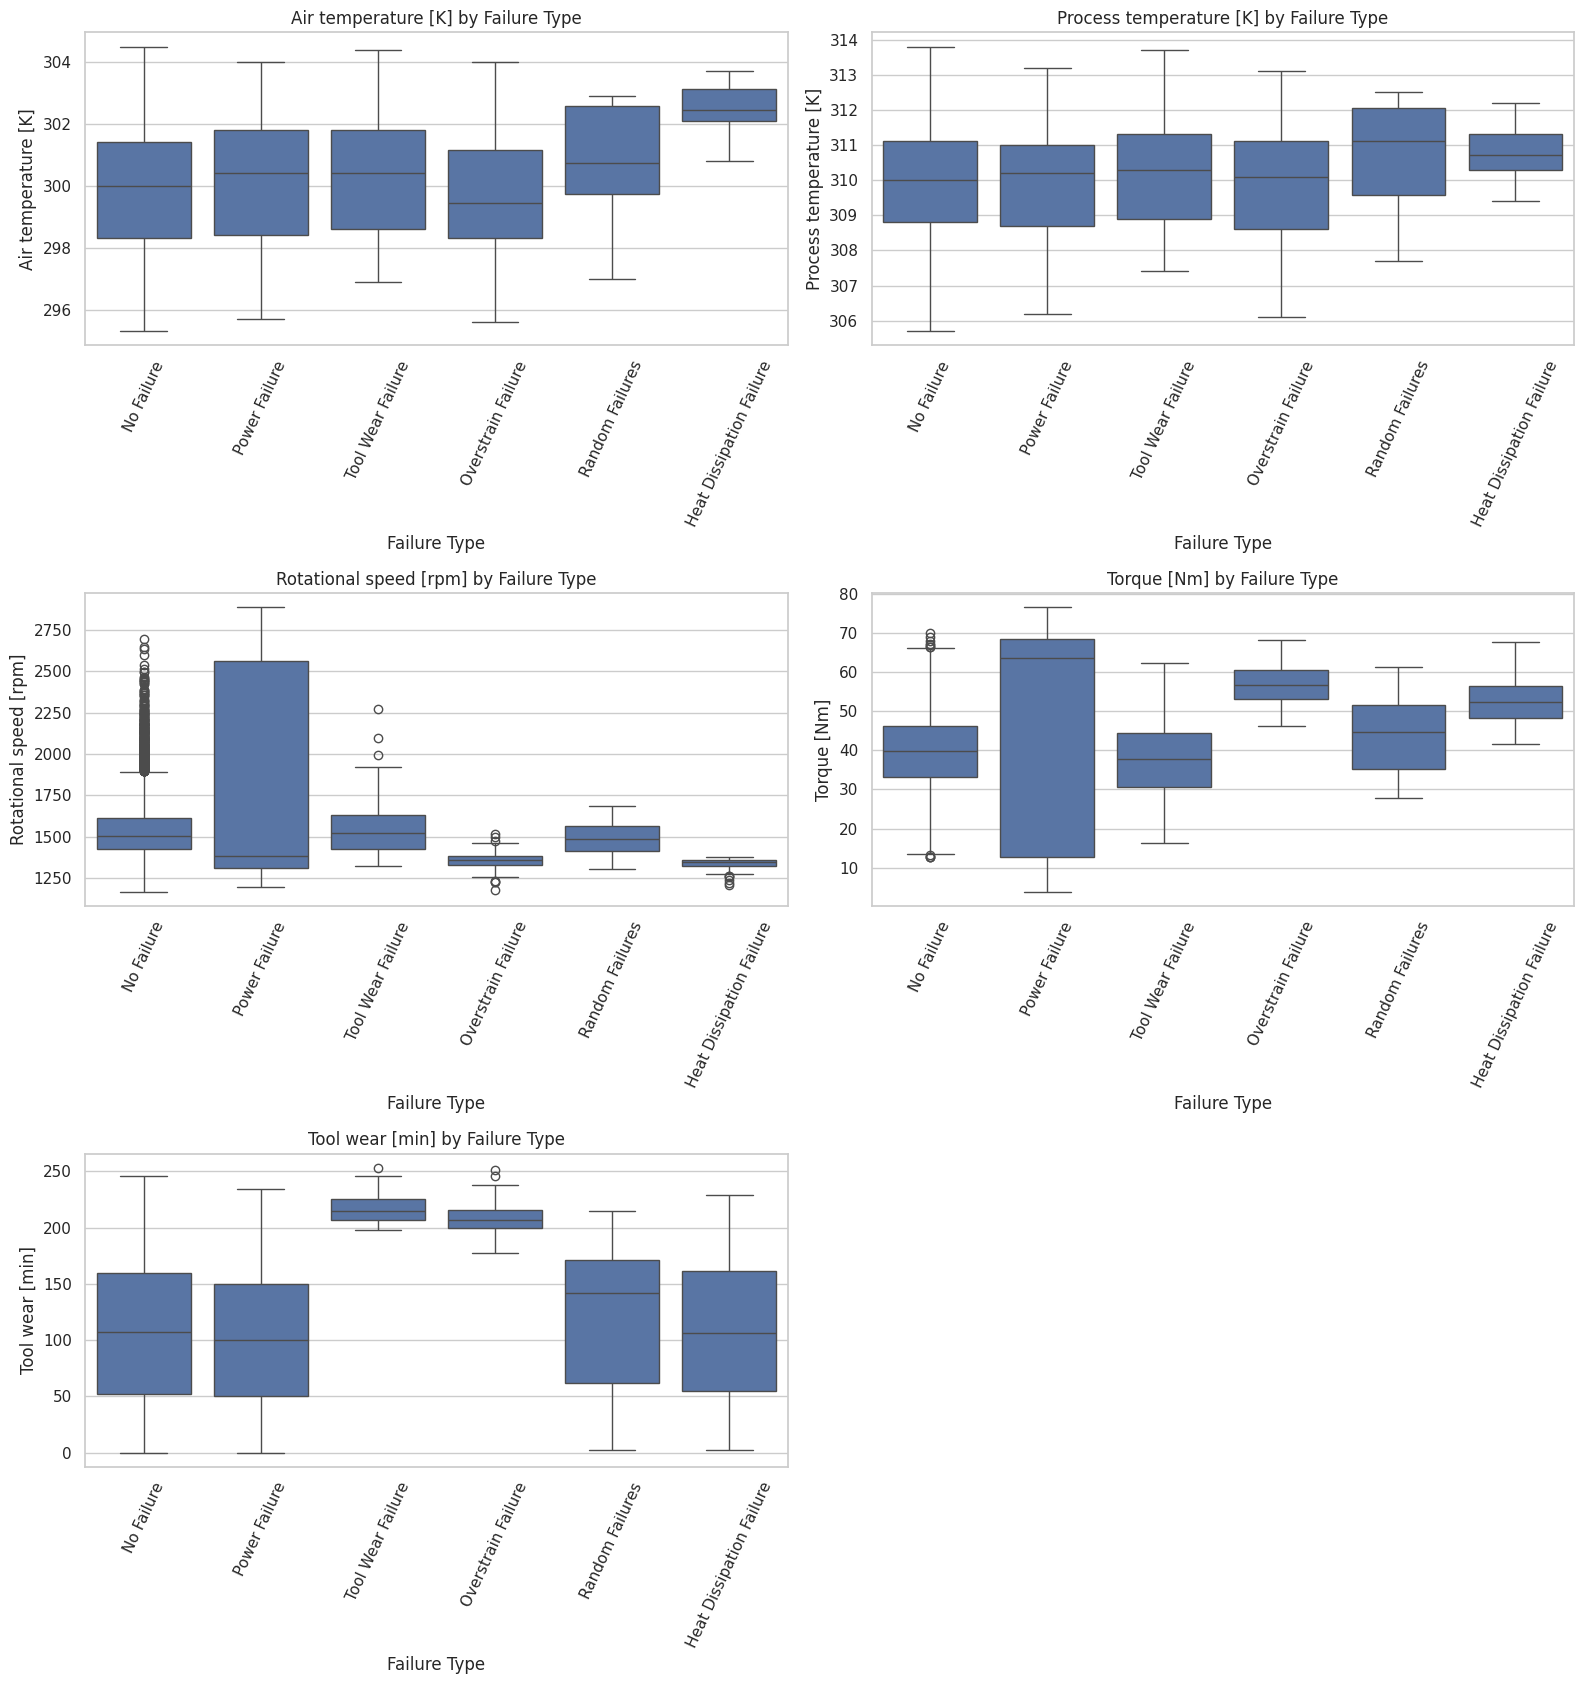

In [39]:

fig, axes = plt.subplots(3, 2, figsize=(16, 17))

axes = axes.flatten()

for i, feature in enumerate(numeric_features):
    sns.boxplot(
        data=maintenance_clean,
        x="Failure Type",
        y=feature,
        ax=axes[i]
    )

    axes[i].set_title(f"{feature} by Failure Type")
    axes[i].tick_params(axis="x", rotation=65)

fig.delaxes(axes[-1])

plt.tight_layout()
plt.show()


Failure Counts by Machine Type:


Failure Type,Heat Dissipation Failure,No Failure,Overstrain Failure,Power Failure,Random Failures,Tool Wear Failure
Type,,,,,,
H,8,979,1,5,4,6
L,74,5757,73,59,12,25
M,30,2916,4,31,2,14


Failure Percentages by Machine Type:


Failure Type,Heat Dissipation Failure,No Failure,Overstrain Failure,Power Failure,Random Failures,Tool Wear Failure
Type,,,,,,
H,0.80,97.61,0.10,0.50,0.40,0.60
L,1.23,95.95,1.22,0.98,0.20,0.42
M,1.00,97.30,0.13,1.03,0.07,0.47


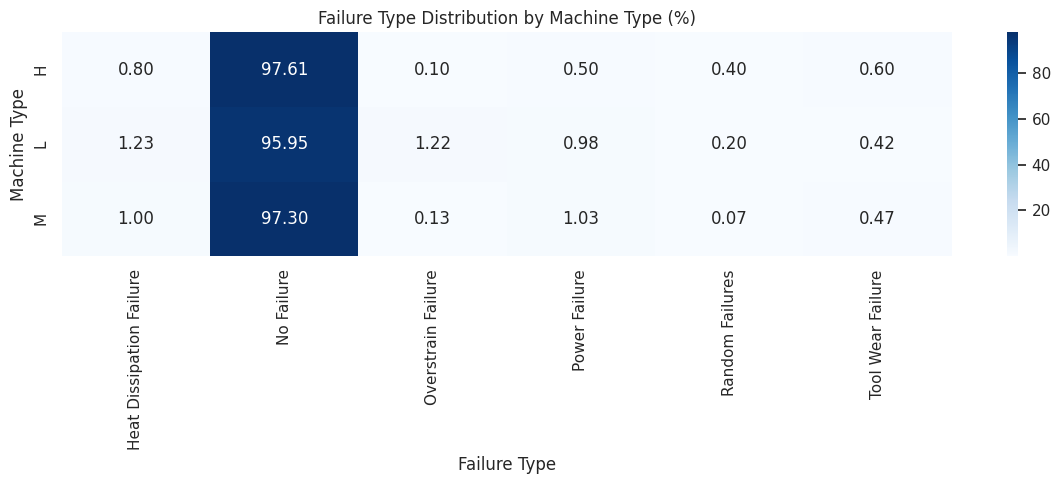

In [40]:

type_failure_counts = pd.crosstab(
    maintenance_clean["Type"],
    maintenance_clean["Failure Type"]
)

type_failure_percentages = pd.crosstab(
    maintenance_clean["Type"],
    maintenance_clean["Failure Type"],
    normalize="index"
) * 100

print("Failure Counts by Machine Type:")
display(type_failure_counts)

print("Failure Percentages by Machine Type:")
display(type_failure_percentages.round(2))

plt.figure(figsize=(12, 5))

sns.heatmap(
    type_failure_percentages,
    annot=True,
    fmt=".2f",
    cmap="Blues"
)

plt.title("Failure Type Distribution by Machine Type (%)")
plt.xlabel("Failure Type")
plt.ylabel("Machine Type")
plt.tight_layout()
plt.show()


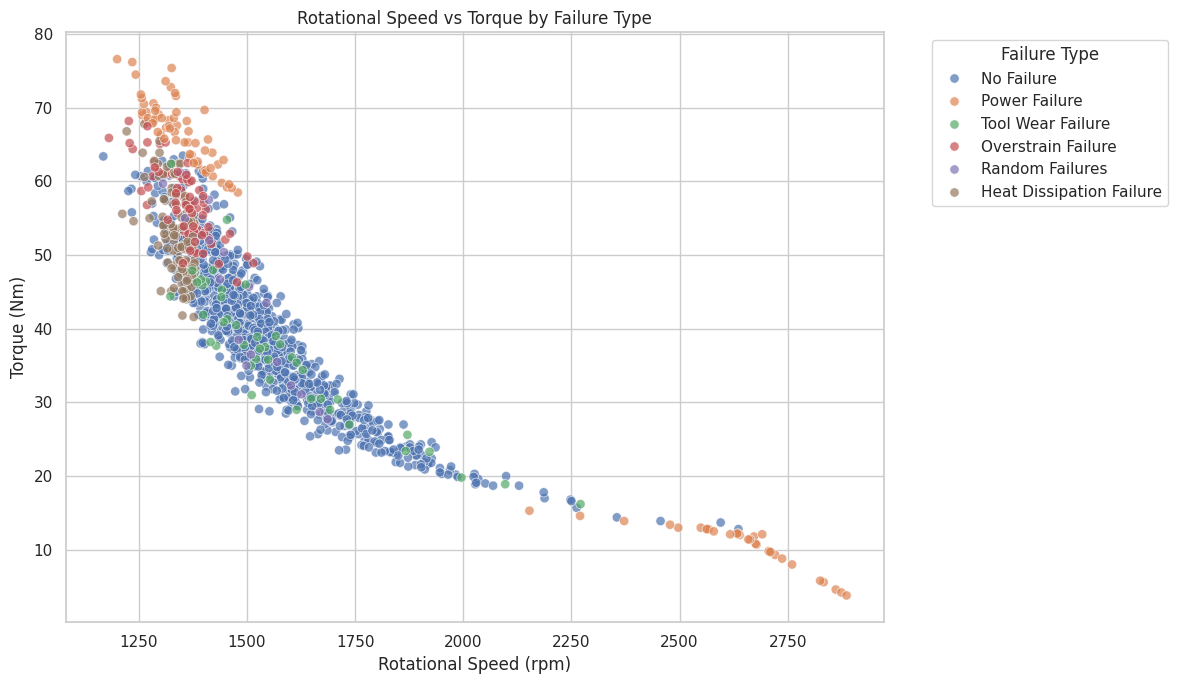

In [41]:

normal_samples = maintenance_clean[
    maintenance_clean["Failure Type"] == "No Failure"
].sample(n=1000, random_state=42)

failure_samples = maintenance_clean[
    maintenance_clean["Failure Type"] != "No Failure"
]

plot_data = pd.concat([
    normal_samples,
    failure_samples
])

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=plot_data,
    x="Rotational speed [rpm]",
    y="Torque [Nm]",
    hue="Failure Type",
    alpha=0.7,
    s=45
)

plt.title("Rotational Speed vs Torque by Failure Type")
plt.xlabel("Rotational Speed (rpm)")
plt.ylabel("Torque (Nm)")
plt.legend(
    title="Failure Type",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


In [42]:

from collections import Counter
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

original_counts = Counter(y_cls_train_np)

original_distribution = pd.DataFrame({
    "Class": label_encoder.classes_,
    "Count": [
        original_counts[i]
        for i in range(len(label_encoder.classes_))
    ]
})

display(original_distribution)

print("Total Training Samples:", len(y_cls_train_np))
print("Number of Classes:", len(original_counts))
print("Imbalance Ratio:", max(original_counts.values()) / min(original_counts.values()))


,Class,Count
0,Heat Dissipation Failure,78
1,No Failure,6756
2,Overstrain Failure,55
3,Power Failure,67
4,Random Failures,13
5,Tool Wear Failure,31


Total Training Samples: 7000
Number of Classes: 6
Imbalance Ratio: 519.6923076923077


In [43]:

from sklearn.preprocessing import StandardScaler

balancing_scaler = StandardScaler()

X_smote_input = X_cls_train.copy()

X_smote_input[numeric_columns] = balancing_scaler.fit_transform(
    X_cls_train[numeric_columns]
)

categorical_indices = [
    X_smote_input.columns.get_loc("Type")
]

print("Input Shape:", X_smote_input.shape)
print("Categorical Feature Indices:", categorical_indices)

display(X_smote_input.head())


Input Shape: (7000, 6)
Categorical Feature Indices: [0]


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
6868,L,0.493074,0.807639,-0.974451,0.629893,-0.723430
8777,H,-1.252940,-0.949378,-0.319077,-0.122863,-1.476526
2927,M,0.343416,-0.273602,-0.652318,0.981180,0.892590
4364,H,1.041822,0.064286,0.425160,-1.016133,1.065174
1338,L,-0.704193,0.064286,1.013886,-1.287126,-1.617732


In [44]:

from imblearn.over_sampling import SMOTENC

target_size = 1500

sampling_strategy = {
    int(cls): target_size
    for cls, count in original_counts.items()
    if count < target_size
}

smote = SMOTENC(
    categorical_features=categorical_indices,
    sampling_strategy=sampling_strategy,
    random_state=42,
    k_neighbors=5
)

X_oversampled, y_oversampled = smote.fit_resample(
    X_smote_input,
    y_cls_train_np
)

print("Original Training Size:", len(y_cls_train_np))
print("Oversampled Training Size:", len(y_oversampled))

print("\nClass Distribution After SMOTENC:")
print(Counter(y_oversampled))


Original Training Size: 7000
Oversampled Training Size: 14256

Class Distribution After SMOTENC:
Counter({np.int64(1): 6756, np.int64(0): 1500, np.int64(5): 1500, np.int64(3): 1500, np.int64(2): 1500, np.int64(4): 1500})


In [45]:

from imblearn.under_sampling import RandomUnderSampler

undersampler = RandomUnderSampler(
    sampling_strategy={1: target_size},
    random_state=42
)

X_balanced_scaled, y_cls_train_balanced = undersampler.fit_resample(
    X_oversampled,
    y_oversampled
)

print("Balanced Training Shape:", X_balanced_scaled.shape)

balanced_counts = Counter(y_cls_train_balanced)

balanced_distribution = pd.DataFrame({
    "Class": label_encoder.classes_,
    "Before": [
        original_counts[i]
        for i in range(len(label_encoder.classes_))
    ],
    "After": [
        balanced_counts[i]
        for i in range(len(label_encoder.classes_))
    ]
})

display(balanced_distribution)

print("Total Balanced Samples:", len(y_cls_train_balanced))


Balanced Training Shape: (9000, 6)


,Class,Before,After
0,Heat Dissipation Failure,78,1500
1,No Failure,6756,1500
2,Overstrain Failure,55,1500
3,Power Failure,67,1500
4,Random Failures,13,1500
5,Tool Wear Failure,31,1500


Total Balanced Samples: 9000


In [46]:

X_balanced_raw = X_balanced_scaled.copy()

X_balanced_raw[numeric_columns] = balancing_scaler.inverse_transform(
    X_balanced_scaled[numeric_columns].astype(float)
)

X_cls_train_balanced_processed = preprocessor.transform(
    X_balanced_raw
)

X_cls_train_balanced_processed = np.asarray(
    X_cls_train_balanced_processed,
    dtype=np.float32
)

y_cls_train_balanced = np.asarray(
    y_cls_train_balanced,
    dtype=np.int64
)

print("Balanced Features Shape:", X_cls_train_balanced_processed.shape)
print("Balanced Target Shape:", y_cls_train_balanced.shape)

print("Missing Values:", np.isnan(X_cls_train_balanced_processed).sum())
print("Infinite Values:", np.isinf(X_cls_train_balanced_processed).sum())

print("Number of Features:", X_cls_train_balanced_processed.shape[1])
print("Number of Classes:", len(np.unique(y_cls_train_balanced)))


Balanced Features Shape: (9000, 8)
Balanced Target Shape: (9000,)
Missing Values: 0
Infinite Values: 0
Number of Features: 8
Number of Classes: 6


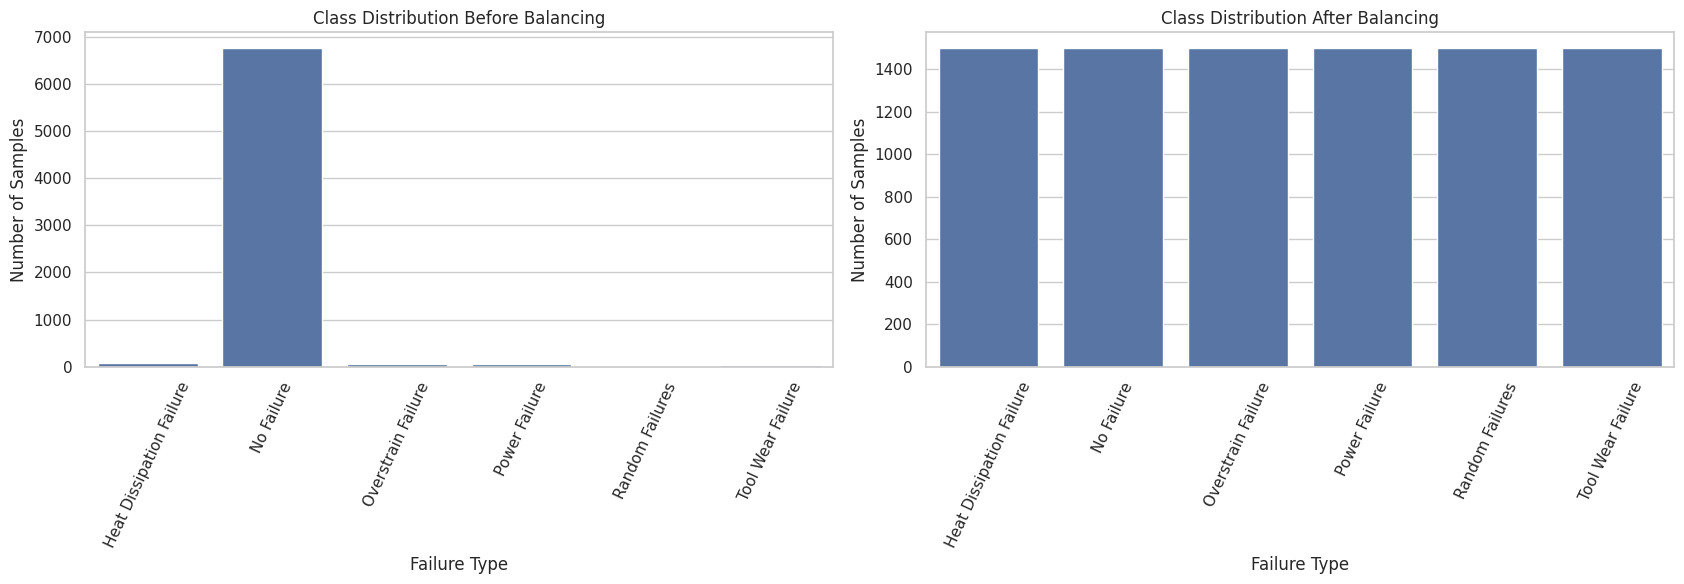

In [47]:

fig, axes = plt.subplots(1, 2, figsize=(17, 6))

sns.barplot(
    data=balanced_distribution,
    x="Class",
    y="Before",
    ax=axes[0]
)

axes[0].set_title("Class Distribution Before Balancing")
axes[0].set_xlabel("Failure Type")
axes[0].set_ylabel("Number of Samples")
axes[0].tick_params(axis="x", rotation=65)

sns.barplot(
    data=balanced_distribution,
    x="Class",
    y="After",
    ax=axes[1]
)

axes[1].set_title("Class Distribution After Balancing")
axes[1].set_xlabel("Failure Type")
axes[1].set_ylabel("Number of Samples")
axes[1].tick_params(axis="x", rotation=65)

plt.tight_layout()
plt.show()


In [48]:

import torch
from torch.utils.data import DataLoader, TensorDataset

X_cls_train_balanced_tensor = torch.tensor(
    X_cls_train_balanced_processed,
    dtype=torch.float32
)

y_cls_train_balanced_tensor = torch.tensor(
    y_cls_train_balanced,
    dtype=torch.long
)

X_cls_val_tensor = torch.tensor(
    X_cls_val_processed,
    dtype=torch.float32
)

y_cls_val_tensor = torch.tensor(
    y_cls_val_np,
    dtype=torch.long
)

X_cls_test_tensor = torch.tensor(
    X_cls_test_processed,
    dtype=torch.float32
)

y_cls_test_tensor = torch.tensor(
    y_cls_test_np,
    dtype=torch.long
)

train_cls_loader = DataLoader(
    TensorDataset(
        X_cls_train_balanced_tensor,
        y_cls_train_balanced_tensor
    ),
    batch_size=128,
    shuffle=True
)

val_cls_loader = DataLoader(
    TensorDataset(
        X_cls_val_tensor,
        y_cls_val_tensor
    ),
    batch_size=128,
    shuffle=False
)

test_cls_loader = DataLoader(
    TensorDataset(
        X_cls_test_tensor,
        y_cls_test_tensor
    ),
    batch_size=128,
    shuffle=False
)

num_classes = len(label_encoder.classes_)
input_size_cls = X_cls_train_balanced_processed.shape[1]

print("Training Samples:", len(train_cls_loader.dataset))
print("Validation Samples:", len(val_cls_loader.dataset))
print("Testing Samples:", len(test_cls_loader.dataset))
print("Input Features:", input_size_cls)
print("Output Classes:", num_classes)
print("Data Balancing and PyTorch Preparation Completed")


Training Samples: 9000
Validation Samples: 1500
Testing Samples: 1500
Input Features: 8
Output Classes: 6
Data Balancing and PyTorch Preparation Completed


In [49]:

import torch
import torch.nn as nn
import numpy as np

torch.manual_seed(42)

cls_device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

class MaintenanceMLP(nn.Module):
    def __init__(self, input_size, num_classes):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        return self.network(x)

cls_baseline_model = MaintenanceMLP(
    input_size=input_size_cls,
    num_classes=num_classes
).to(cls_device)

cls_baseline_criterion = nn.CrossEntropyLoss()

cls_baseline_optimizer = torch.optim.Adam(
    cls_baseline_model.parameters(),
    lr=0.001
)

print(cls_baseline_model)
print("\nDevice:", cls_device)
print("Input Features:", input_size_cls)
print("Output Classes:", num_classes)


MaintenanceMLP(
  (network): Sequential(
    (0): Linear(in_features=8, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=6, bias=True)
  )
)

Device: cuda
Input Features: 8
Output Classes: 6


In [51]:

cls_epochs = 60

cls_train_losses = []
cls_val_losses = []
cls_train_accuracies = []
cls_val_accuracies = []

for epoch in range(cls_epochs):
    cls_baseline_model.train()

    train_loss = 0
    train_correct = 0
    train_total = 0

    for X_batch, y_batch in train_cls_loader:
        X_batch = X_batch.to(cls_device)
        y_batch = y_batch.to(cls_device)

        cls_baseline_optimizer.zero_grad()

        outputs = cls_baseline_model(X_batch)

        loss = cls_baseline_criterion(outputs, y_batch)

        loss.backward()
        cls_baseline_optimizer.step()

        train_loss += loss.item() * X_batch.size(0)

        predictions = torch.argmax(outputs, dim=1)

        train_correct += (predictions == y_batch).sum().item()
        train_total += y_batch.size(0)

    train_loss /= train_total
    train_accuracy = 100 * train_correct / train_total

    cls_baseline_model.eval()

    val_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for X_batch, y_batch in val_cls_loader:
            X_batch = X_batch.to(cls_device)
            y_batch = y_batch.to(cls_device)

            outputs = cls_baseline_model(X_batch)

            loss = cls_baseline_criterion(outputs, y_batch)

            val_loss += loss.item() * X_batch.size(0)

            predictions = torch.argmax(outputs, dim=1)

            val_correct += (predictions == y_batch).sum().item()
            val_total += y_batch.size(0)

    val_loss /= val_total
    val_accuracy = 100 * val_correct / val_total

    cls_train_losses.append(train_loss)
    cls_val_losses.append(val_loss)
    cls_train_accuracies.append(train_accuracy)
    cls_val_accuracies.append(val_accuracy)

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch [{epoch+1}/{cls_epochs}] | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Train Acc: {train_accuracy:.2f}% | "
            f"Val Acc: {val_accuracy:.2f}%"
        )


Epoch [10/60] | Train Loss: 0.0342 | Val Loss: 0.3520 | Train Acc: 99.10% | Val Acc: 91.73%
Epoch [20/60] | Train Loss: 0.0308 | Val Loss: 0.3882 | Train Acc: 99.20% | Val Acc: 91.67%
Epoch [30/60] | Train Loss: 0.0273 | Val Loss: 0.3493 | Train Acc: 99.34% | Val Acc: 93.07%
Epoch [40/60] | Train Loss: 0.0230 | Val Loss: 0.3992 | Train Acc: 99.44% | Val Acc: 92.13%
Epoch [50/60] | Train Loss: 0.0224 | Val Loss: 0.3663 | Train Acc: 99.40% | Val Acc: 93.67%
Epoch [60/60] | Train Loss: 0.0221 | Val Loss: 0.4262 | Train Acc: 99.38% | Val Acc: 92.00%


In [52]:

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

cls_baseline_model.eval()

val_predictions = []
val_actual = []

with torch.no_grad():
    for X_batch, y_batch in val_cls_loader:
        X_batch = X_batch.to(cls_device)

        outputs = cls_baseline_model(X_batch)

        predictions = torch.argmax(outputs, dim=1)

        val_predictions.extend(
            predictions.cpu().numpy()
        )

        val_actual.extend(
            y_batch.numpy()
        )

val_predictions = np.array(val_predictions)
val_actual = np.array(val_actual)

cls_baseline_val_accuracy = accuracy_score(
    val_actual, val_predictions
)

cls_baseline_val_f1 = f1_score(
    val_actual,
    val_predictions,
    average="macro",
    zero_division=0
)

cls_baseline_val_balanced_accuracy = balanced_accuracy_score(
    val_actual,
    val_predictions
)

print("Baseline MLP - Validation Results")
print(f"Accuracy: {cls_baseline_val_accuracy:.4f}")
print(f"Macro F1-Score: {cls_baseline_val_f1:.4f}")
print(f"Balanced Accuracy: {cls_baseline_val_balanced_accuracy:.4f}")

prediction_distribution = pd.DataFrame({
    "Class": label_encoder.classes_,
    "Actual": np.bincount(
        val_actual, minlength=num_classes
    ),
    "Predicted": np.bincount(
        val_predictions, minlength=num_classes
    )
})

display(prediction_distribution)


Baseline MLP - Validation Results
Accuracy: 0.9200
Macro F1-Score: 0.4895
Balanced Accuracy: 0.5939


,Class,Actual,Predicted
0,Heat Dissipation Failure,17,31
1,No Failure,1448,1354
2,Overstrain Failure,11,20
3,Power Failure,14,19
4,Random Failures,3,50
5,Tool Wear Failure,7,26


In [53]:

cls_baseline_results = {
    "Model": "Baseline MLP",
    "Validation Accuracy": cls_baseline_val_accuracy,
    "Validation Macro F1": cls_baseline_val_f1,
    "Validation Balanced Accuracy": cls_baseline_val_balanced_accuracy
}

torch.save(
    {
        "model_state_dict": cls_baseline_model.state_dict(),
        "input_size": input_size_cls,
        "num_classes": num_classes,
        "train_losses": cls_train_losses,
        "val_losses": cls_val_losses,
        "train_accuracies": cls_train_accuracies,
        "val_accuracies": cls_val_accuracies
    },
    "/kaggle/working/maintenance_mlp_baseline.pth"
)

print("Baseline Model Saved Successfully")
print("File: /kaggle/working/maintenance_mlp_baseline.pth")


Baseline Model Saved Successfully
File: /kaggle/working/maintenance_mlp_baseline.pth


In [55]:

import torch
import torch.nn as nn
import numpy as np

from sklearn.base import BaseEstimator, ClassifierMixin
from torch.utils.data import TensorDataset, DataLoader

class TorchMaintenanceClassifier(ClassifierMixin, BaseEstimator):
    def __init__(
        self,
        hidden_layers=(64, 32),
        optimizer_name="adam",
        learning_rate=0.001,
        epochs=20,
        batch_size=256
    ):
        self.hidden_layers = hidden_layers
        self.optimizer_name = optimizer_name
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.batch_size = batch_size

    def fit(self, X, y):
        torch.manual_seed(42)

        X_arr = np.asarray(X, dtype=np.float32)
        y_arr = np.asarray(y, dtype=np.int64).ravel()

        self.classes_ = np.unique(y_arr)
        y_indices = np.searchsorted(self.classes_, y_arr)

        layers = []
        input_dim = X_arr.shape[1]

        for units in self.hidden_layers:
            layers.append(nn.Linear(input_dim, units))
            layers.append(nn.ReLU())
            input_dim = units

        layers.append(nn.Linear(input_dim, len(self.classes_)))

        self.device_ = torch.device(
            "cuda" if torch.cuda.is_available() else "cpu"
        )

        self.model_ = nn.Sequential(*layers).to(self.device_)

        optimizer_class = {
            "adam": torch.optim.Adam,
            "rmsprop": torch.optim.RMSprop
        }[self.optimizer_name]

        optimizer = optimizer_class(
            self.model_.parameters(),
            lr=self.learning_rate
        )

        dataset = TensorDataset(
            torch.from_numpy(X_arr),
            torch.from_numpy(y_indices.astype(np.int64))
        )

        loader = DataLoader(
            dataset,
            batch_size=self.batch_size,
            shuffle=True,
            generator=torch.Generator().manual_seed(42)
        )

        criterion = nn.CrossEntropyLoss()

        for epoch in range(self.epochs):
            self.model_.train()

            for xb, yb in loader:
                xb = xb.to(self.device_)
                yb = yb.to(self.device_)

                optimizer.zero_grad()

                outputs = self.model_(xb)
                loss = criterion(outputs, yb)

                loss.backward()
                optimizer.step()

        return self

    def predict_proba(self, X):
        X_arr = np.asarray(X, dtype=np.float32)

        self.model_.eval()

        with torch.no_grad():
            inputs = torch.from_numpy(X_arr).to(self.device_)
            outputs = self.model_(inputs)
            probabilities = torch.softmax(outputs, dim=1)

        return probabilities.cpu().numpy()

    def predict(self, X):
        probabilities = self.predict_proba(X)
        indices = np.argmax(probabilities, axis=1)

        return self.classes_[indices]


In [56]:

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTENC
from imblearn.under_sampling import RandomUnderSampler

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder

cv_numeric_columns = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

cv_preprocessor = ColumnTransformer([
    (
        "numeric",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]),
        cv_numeric_columns
    ),
    (
        "categorical",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("ordinal", OrdinalEncoder(
                handle_unknown="use_encoded_value",
                unknown_value=-1
            ))
        ]),
        ["Type"]
    )
])

cv_encoder = ColumnTransformer([
    (
        "numeric",
        "passthrough",
        list(range(5))
    ),
    (
        "categorical",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ),
        [5]
    )
])

cls_grid_pipeline = ImbPipeline([
    ("preprocessing", cv_preprocessor),
    ("smote", SMOTENC(
        categorical_features=[5],
        sampling_strategy={
            0: 300,
            2: 300,
            3: 300,
            4: 300,
            5: 300
        },
        k_neighbors=3,
        random_state=42
    )),
    ("undersampling", RandomUnderSampler(
        sampling_strategy={1: 300},
        random_state=42
    )),
    ("encoding", cv_encoder),
    ("classifier", TorchMaintenanceClassifier())
])

print("Cross-Validation Pipeline Ready")
print(cls_grid_pipeline)


Cross-Validation Pipeline Ready
Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Air temperature [K]',
                                                   'Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                  

In [59]:

from sklearn.model_selection import GridSearchCV, StratifiedKFold

cls_param_grid = {
    "classifier__hidden_layers": [
        (64, 32),
        (128, 64)
    ],
    "classifier__optimizer_name": [
        "adam",
        "rmsprop"
    ],
    "classifier__learning_rate": [
        0.001,
        0.003
    ],
    "classifier__epochs": [
        20,
        40
    ]
}

cls_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

cls_grid = GridSearchCV(
    estimator=cls_grid_pipeline,
    param_grid=cls_param_grid,
    scoring="f1_macro",
    cv=cls_cv,
    n_jobs=1,
    verbose=1,
    refit=True,
    error_score="raise",
    return_train_score=True
)

cls_grid.fit(
    X_cls_train,
    y_cls_train_np
)

print("\nBest Hyperparameters:")
print(cls_grid.best_params_)

print("\nBest Cross-Validation Macro F1:")
print(round(cls_grid.best_score_, 4))


Fitting 3 folds for each of 16 candidates, totalling 48 fits

Best Hyperparameters:
{'classifier__epochs': 40, 'classifier__hidden_layers': (128, 64), 'classifier__learning_rate': 0.003, 'classifier__optimizer_name': 'rmsprop'}

Best Cross-Validation Macro F1:
0.4378


In [60]:

cls_cv_results = pd.DataFrame(cls_grid.cv_results_)

cls_cv_summary = cls_cv_results[[
    "param_classifier__hidden_layers",
    "param_classifier__optimizer_name",
    "param_classifier__learning_rate",
    "param_classifier__epochs",
    "mean_train_score",
    "mean_test_score",
    "std_test_score",
    "rank_test_score"
]].copy()

cls_cv_summary.columns = [
    "Hidden Layers",
    "Optimizer",
    "Learning Rate",
    "Epochs",
    "Train Macro F1",
    "CV Macro F1",
    "CV Std",
    "Rank"
]

cls_cv_summary = cls_cv_summary.sort_values("Rank")

display(cls_cv_summary.round(4))

print("\nTop 5 Configurations:")
display(cls_cv_summary.head(5).round(4))


,Hidden Layers,Optimizer,Learning Rate,Epochs,Train Macro F1,CV Macro F1,CV Std,Rank
15,"(128, 64)",rmsprop,0.003,40,0.4773,0.4378,0.0364,1
11,"(64, 32)",rmsprop,0.003,40,0.4525,0.4201,0.0327,2
14,"(128, 64)",adam,0.003,40,0.4591,0.4182,0.0126,3
13,"(128, 64)",rmsprop,0.001,40,0.4391,0.4103,0.0213,4
10,"(64, 32)",adam,0.003,40,0.4099,0.3880,0.0245,5
6,"(128, 64)",adam,0.003,20,0.4091,0.3800,0.0058,6
12,"(128, 64)",adam,0.001,40,0.3936,0.3751,0.0141,7
9,"(64, 32)",rmsprop,0.001,40,0.3784,0.3640,0.0126,8
7,"(128, 64)",rmsprop,0.003,20,0.3919,0.3611,0.0376,9
2,"(64, 32)",adam,0.003,20,0.3652,0.3522,0.0094,10



Top 5 Configurations:


,Hidden Layers,Optimizer,Learning Rate,Epochs,Train Macro F1,CV Macro F1,CV Std,Rank
15,"(128, 64)",rmsprop,0.003,40,0.4773,0.4378,0.0364,1
11,"(64, 32)",rmsprop,0.003,40,0.4525,0.4201,0.0327,2
14,"(128, 64)",adam,0.003,40,0.4591,0.4182,0.0126,3
13,"(128, 64)",rmsprop,0.001,40,0.4391,0.4103,0.0213,4
10,"(64, 32)",adam,0.003,40,0.4099,0.3880,0.0245,5


In [61]:

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

cls_optimized_model = cls_grid.best_estimator_

cls_optimized_val_pred = cls_optimized_model.predict(
    X_cls_val
)

cls_optimized_val_accuracy = accuracy_score(
    y_cls_val_np,
    cls_optimized_val_pred
)

cls_optimized_val_f1 = f1_score(
    y_cls_val_np,
    cls_optimized_val_pred,
    average="macro",
    zero_division=0
)

cls_optimized_val_balanced_accuracy = balanced_accuracy_score(
    y_cls_val_np,
    cls_optimized_val_pred
)

print("Optimized MLP - Validation Results")

print(f"Accuracy: {cls_optimized_val_accuracy:.4f}")
print(f"Macro F1: {cls_optimized_val_f1:.4f}")
print(f"Balanced Accuracy: {cls_optimized_val_balanced_accuracy:.4f}")

cls_optimized_distribution = pd.DataFrame({
    "Class": label_encoder.classes_,
    "Actual": np.bincount(
        y_cls_val_np,
        minlength=num_classes
    ),
    "Predicted": np.bincount(
        cls_optimized_val_pred,
        minlength=num_classes
    )
})

display(cls_optimized_distribution)


Optimized MLP - Validation Results
Accuracy: 0.8273
Macro F1: 0.4363
Balanced Accuracy: 0.6361


,Class,Actual,Predicted
0,Heat Dissipation Failure,17,42
1,No Failure,1448,1211
2,Overstrain Failure,11,22
3,Power Failure,14,28
4,Random Failures,3,136
5,Tool Wear Failure,7,61


,Model,Accuracy,Macro F1,Balanced Accuracy
0,Baseline MLP,0.9200,0.4895,0.5939
1,Optimized MLP,0.8273,0.4363,0.6361


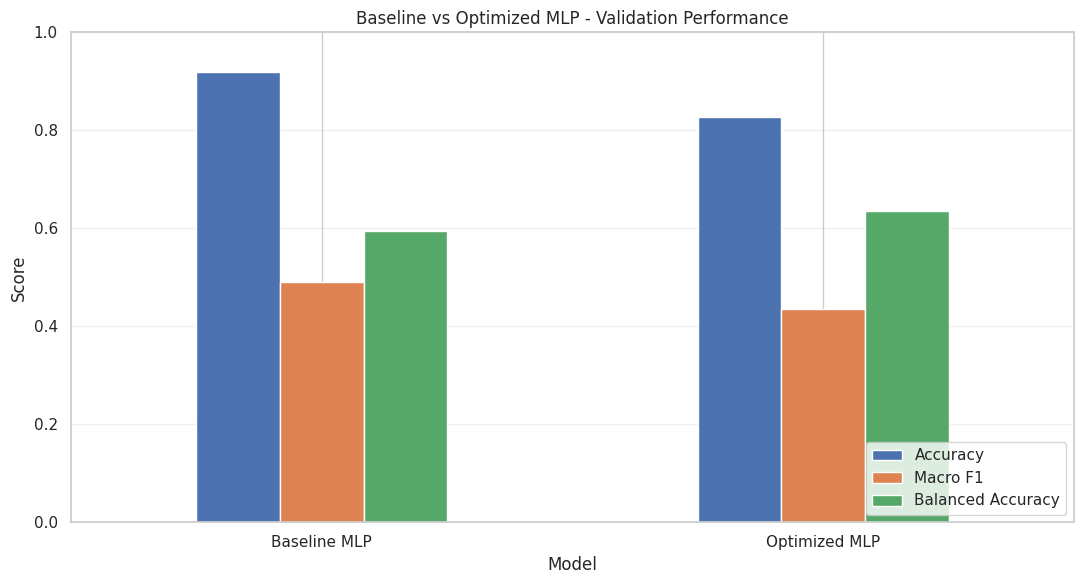

Comparison Saved Successfully


In [62]:

cls_model_comparison = pd.DataFrame({
    "Model": [
        "Baseline MLP",
        "Optimized MLP"
    ],
    "Accuracy": [
        cls_baseline_val_accuracy,
        cls_optimized_val_accuracy
    ],
    "Macro F1": [
        cls_baseline_val_f1,
        cls_optimized_val_f1
    ],
    "Balanced Accuracy": [
        cls_baseline_val_balanced_accuracy,
        cls_optimized_val_balanced_accuracy
    ]
})

display(cls_model_comparison.round(4))

cls_model_comparison.set_index("Model").plot(
    kind="bar",
    figsize=(11, 6),
    rot=0
)

plt.title("Baseline vs Optimized MLP - Validation Performance")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

cls_model_comparison.to_csv(
    "/kaggle/working/classification_gridsearch_comparison.csv",
    index=False
)

print("Comparison Saved Successfully")


In [63]:

import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader, TensorDataset

best_pipeline = cls_grid.best_estimator_

fitted_preprocessor = best_pipeline.named_steps["preprocessing"]
fitted_smote = best_pipeline.named_steps["smote"]
fitted_undersampler = best_pipeline.named_steps["undersampling"]
fitted_encoder = best_pipeline.named_steps["encoding"]

X_curve_train_raw = fitted_preprocessor.transform(X_cls_train)

X_curve_smote, y_curve_smote = fitted_smote.fit_resample(
    X_curve_train_raw,
    y_cls_train_np
)

X_curve_balanced, y_curve_balanced = fitted_undersampler.fit_resample(
    X_curve_smote,
    y_curve_smote
)

X_curve_train = fitted_encoder.transform(X_curve_balanced)

X_curve_val = fitted_encoder.transform(
    fitted_preprocessor.transform(X_cls_val)
)

X_curve_test = fitted_encoder.transform(
    fitted_preprocessor.transform(X_cls_test)
)

X_curve_train = np.asarray(X_curve_train, dtype=np.float32)
X_curve_val = np.asarray(X_curve_val, dtype=np.float32)
X_curve_test = np.asarray(X_curve_test, dtype=np.float32)

y_curve_train = np.asarray(y_curve_balanced, dtype=np.int64)

print("Training Shape:", X_curve_train.shape)
print("Validation Shape:", X_curve_val.shape)
print("Testing Shape:", X_curve_test.shape)

print("Training Class Distribution:")
print(np.bincount(y_curve_train))


Training Shape: (1800, 8)
Validation Shape: (1500, 8)
Testing Shape: (1500, 8)
Training Class Distribution:
[300 300 300 300 300 300]


In [64]:

torch.manual_seed(42)
np.random.seed(42)

cls_curve_device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

best_classifier = best_pipeline.named_steps["classifier"]

curve_layers = []
curve_input_dim = X_curve_train.shape[1]

for units in best_classifier.hidden_layers:
    curve_layers.append(nn.Linear(curve_input_dim, units))
    curve_layers.append(nn.ReLU())
    curve_input_dim = units

curve_layers.append(nn.Linear(curve_input_dim, num_classes))

cls_curve_model = nn.Sequential(*curve_layers).to(cls_curve_device)

cls_curve_criterion = nn.CrossEntropyLoss()

optimizer_options = {
    "adam": torch.optim.Adam,
    "rmsprop": torch.optim.RMSprop
}

cls_curve_optimizer = optimizer_options[
    best_classifier.optimizer_name
](
    cls_curve_model.parameters(),
    lr=best_classifier.learning_rate
)

curve_train_dataset = TensorDataset(
    torch.tensor(X_curve_train, dtype=torch.float32),
    torch.tensor(y_curve_train, dtype=torch.long)
)

curve_train_loader = DataLoader(
    curve_train_dataset,
    batch_size=best_classifier.batch_size,
    shuffle=True,
    generator=torch.Generator().manual_seed(42)
)

curve_train_X = torch.tensor(
    X_curve_train, dtype=torch.float32
).to(cls_curve_device)

curve_train_y = torch.tensor(
    y_curve_train, dtype=torch.long
).to(cls_curve_device)

curve_val_X = torch.tensor(
    X_curve_val, dtype=torch.float32
).to(cls_curve_device)

curve_val_y = torch.tensor(
    y_cls_val_np, dtype=torch.long
).to(cls_curve_device)

curve_test_X = torch.tensor(
    X_curve_test, dtype=torch.float32
).to(cls_curve_device)

curve_test_y = torch.tensor(
    y_cls_test_np, dtype=torch.long
).to(cls_curve_device)

print(cls_curve_model)
print("Device:", cls_curve_device)
print("Epochs:", best_classifier.epochs)


Sequential(
  (0): Linear(in_features=8, out_features=128, bias=True)
  (1): ReLU()
  (2): Linear(in_features=128, out_features=64, bias=True)
  (3): ReLU()
  (4): Linear(in_features=64, out_features=6, bias=True)
)
Device: cuda
Epochs: 40


In [65]:

curve_epochs = best_classifier.epochs

curve_train_losses = []
curve_val_losses = []
curve_test_losses = []

curve_train_accuracies = []
curve_val_accuracies = []
curve_test_accuracies = []

def evaluate_curve(model, X, y):
    model.eval()

    with torch.no_grad():
        outputs = model(X)
        loss = cls_curve_criterion(outputs, y).item()
        predictions = torch.argmax(outputs, dim=1)
        accuracy = (predictions == y).float().mean().item() * 100

    return loss, accuracy

for epoch in range(curve_epochs):
    cls_curve_model.train()

    for xb, yb in curve_train_loader:
        xb = xb.to(cls_curve_device)
        yb = yb.to(cls_curve_device)

        cls_curve_optimizer.zero_grad()

        outputs = cls_curve_model(xb)
        loss = cls_curve_criterion(outputs, yb)

        loss.backward()
        cls_curve_optimizer.step()

    train_loss, train_acc = evaluate_curve(
        cls_curve_model, curve_train_X, curve_train_y
    )

    val_loss, val_acc = evaluate_curve(
        cls_curve_model, curve_val_X, curve_val_y
    )

    test_loss, test_acc = evaluate_curve(
        cls_curve_model, curve_test_X, curve_test_y
    )

    curve_train_losses.append(train_loss)
    curve_val_losses.append(val_loss)
    curve_test_losses.append(test_loss)

    curve_train_accuracies.append(train_acc)
    curve_val_accuracies.append(val_acc)
    curve_test_accuracies.append(test_acc)

    if (epoch + 1) % 5 == 0:
        print(
            f"Epoch [{epoch+1}/{curve_epochs}] | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Test Loss: {test_loss:.4f} | "
            f"Train Acc: {train_acc:.2f}% | "
            f"Val Acc: {val_acc:.2f}% | "
            f"Test Acc: {test_acc:.2f}%"
        )


Epoch [5/40] | Train Loss: 0.9566 | Val Loss: 0.6273 | Test Loss: 0.6264 | Train Acc: 64.72% | Val Acc: 72.53% | Test Acc: 72.53%
Epoch [10/40] | Train Loss: 0.3675 | Val Loss: 0.3418 | Test Loss: 0.3469 | Train Acc: 84.44% | Val Acc: 86.27% | Test Acc: 87.00%
Epoch [15/40] | Train Loss: 0.2412 | Val Loss: 0.4494 | Test Loss: 0.4648 | Train Acc: 90.22% | Val Acc: 80.93% | Test Acc: 80.07%
Epoch [20/40] | Train Loss: 0.1911 | Val Loss: 0.6922 | Test Loss: 0.7142 | Train Acc: 93.67% | Val Acc: 70.73% | Test Acc: 69.93%
Epoch [25/40] | Train Loss: 0.3696 | Val Loss: 1.4868 | Test Loss: 1.4774 | Train Acc: 89.39% | Val Acc: 56.80% | Test Acc: 59.13%
Epoch [30/40] | Train Loss: 0.3210 | Val Loss: 0.5428 | Test Loss: 0.5827 | Train Acc: 89.39% | Val Acc: 76.87% | Test Acc: 78.07%
Epoch [35/40] | Train Loss: 0.6181 | Val Loss: 0.7426 | Test Loss: 0.7557 | Train Acc: 84.67% | Val Acc: 73.80% | Test Acc: 72.80%
Epoch [40/40] | Train Loss: 0.1200 | Val Loss: 0.4398 | Test Loss: 0.4622 | Train Ac

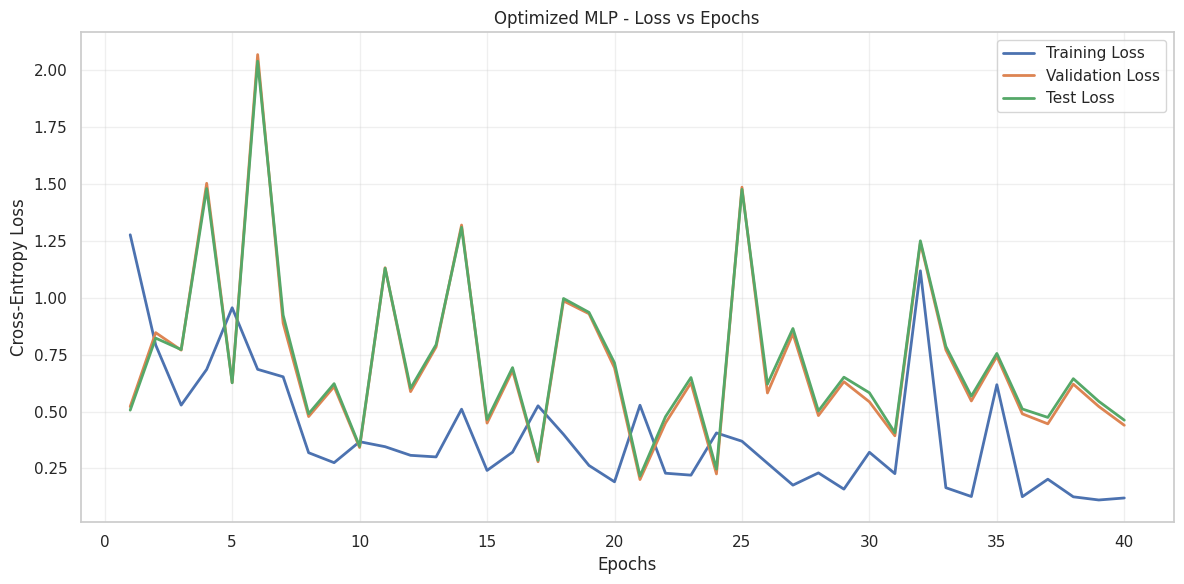

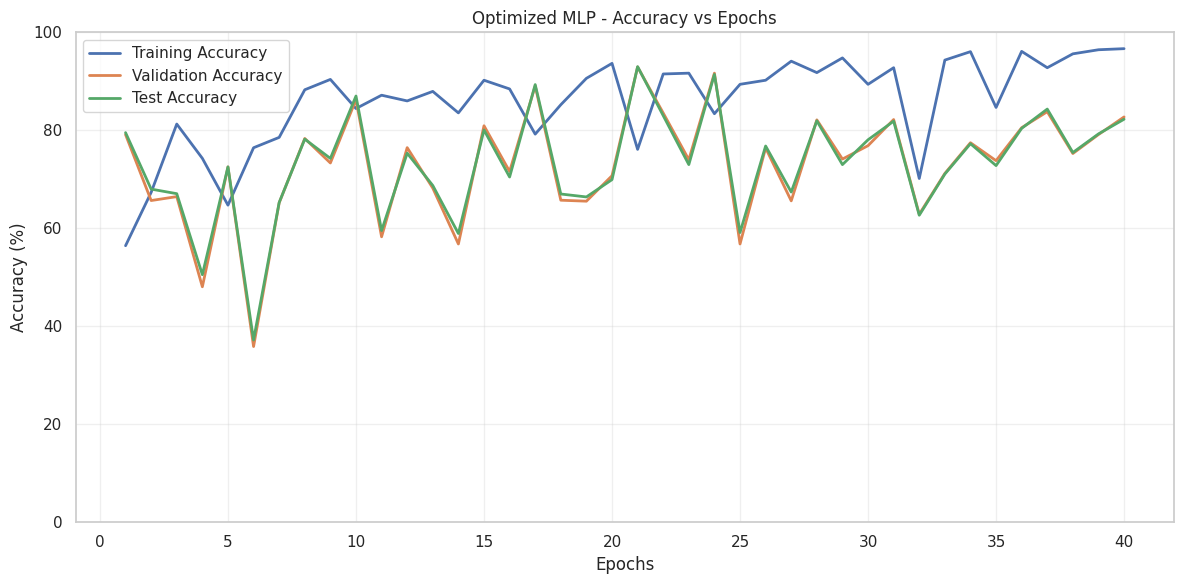

In [66]:

epoch_range = range(1, curve_epochs + 1)

plt.figure(figsize=(12, 6))

plt.plot(
    epoch_range,
    curve_train_losses,
    label="Training Loss",
    linewidth=2
)

plt.plot(
    epoch_range,
    curve_val_losses,
    label="Validation Loss",
    linewidth=2
)

plt.plot(
    epoch_range,
    curve_test_losses,
    label="Test Loss",
    linewidth=2
)

plt.title("Optimized MLP - Loss vs Epochs")
plt.xlabel("Epochs")
plt.ylabel("Cross-Entropy Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 6))

plt.plot(
    epoch_range,
    curve_train_accuracies,
    label="Training Accuracy",
    linewidth=2
)

plt.plot(
    epoch_range,
    curve_val_accuracies,
    label="Validation Accuracy",
    linewidth=2
)

plt.plot(
    epoch_range,
    curve_test_accuracies,
    label="Test Accuracy",
    linewidth=2
)

plt.title("Optimized MLP - Accuracy vs Epochs")
plt.xlabel("Epochs")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [67]:

curve_summary = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Test"],
    "Final Loss": [
        curve_train_losses[-1],
        curve_val_losses[-1],
        curve_test_losses[-1]
    ],
    "Final Accuracy (%)": [
        curve_train_accuracies[-1],
        curve_val_accuracies[-1],
        curve_test_accuracies[-1]
    ]
})

display(curve_summary.round(4))

curve_history = pd.DataFrame({
    "Epoch": list(epoch_range),
    "Train Loss": curve_train_losses,
    "Validation Loss": curve_val_losses,
    "Test Loss": curve_test_losses,
    "Train Accuracy": curve_train_accuracies,
    "Validation Accuracy": curve_val_accuracies,
    "Test Accuracy": curve_test_accuracies
})

curve_history.to_csv(
    "/kaggle/working/classification_learning_curves.csv",
    index=False
)

print("Learning Curves Saved Successfully")


,Dataset,Final Loss,Final Accuracy (%)
0,Training,0.1200,96.6667
1,Validation,0.4398,82.7333
2,Test,0.4622,82.2667


Learning Curves Saved Successfully


In [68]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report,
    precision_recall_fscore_support
)

cls_curve_model.eval()

with torch.no_grad():
    train_outputs = cls_curve_model(curve_train_X)
    test_outputs = cls_curve_model(curve_test_X)

    y_train_pred = torch.argmax(
        train_outputs, dim=1
    ).cpu().numpy()

    y_test_pred = torch.argmax(
        test_outputs, dim=1
    ).cpu().numpy()

y_train_true = curve_train_y.cpu().numpy()
y_test_true = curve_test_y.cpu().numpy()

print("Training Samples:", len(y_train_true))
print("Test Samples:", len(y_test_true))

print("\nTraining Predictions:")
print(y_train_pred[:20])

print("\nTest Predictions:")
print(y_test_pred[:20])


Training Samples: 1800
Test Samples: 1500

Training Predictions:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]

Test Predictions:
[1 4 1 1 3 5 4 1 1 1 1 4 4 1 1 4 1 1 5 5]


In [69]:

def evaluate_classification(y_true, y_pred, dataset_name):
    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=np.arange(num_classes)
    )

    tn = cm.sum() - (
        cm.sum(axis=0) + cm.sum(axis=1) - np.diag(cm)
    )

    fp = cm.sum(axis=0) - np.diag(cm)

    specificity = np.divide(
        tn,
        tn + fp,
        out=np.zeros_like(tn, dtype=float),
        where=(tn + fp) != 0
    ).mean()

    return {
        "Dataset": dataset_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision Macro": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Recall Macro": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "F1 Macro": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "F1 Weighted": f1_score(
            y_true, y_pred, average="weighted", zero_division=0
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            y_true, y_pred
        ),
        "Specificity Macro": specificity
    }

train_metrics = evaluate_classification(
    y_train_true,
    y_train_pred,
    "Training"
)

test_metrics = evaluate_classification(
    y_test_true,
    y_test_pred,
    "Test"
)

metrics_comparison = pd.DataFrame([
    train_metrics,
    test_metrics
])

display(metrics_comparison.round(4))


,Dataset,Accuracy,Precision Macro,Recall Macro,F1 Macro,F1 Weighted,Balanced Accuracy,Specificity Macro
0,Training,0.9667,0.9674,0.9667,0.9662,0.9662,0.9667,0.9933
1,Test,0.8227,0.4153,0.6729,0.4778,0.8874,0.6729,0.9518


In [70]:

print("TRAINING CLASSIFICATION REPORT")

print(
    classification_report(
        y_train_true,
        y_train_pred,
        labels=np.arange(num_classes),
        target_names=label_encoder.classes_,
        zero_division=0,
        digits=4
    )
)

print("\nTEST CLASSIFICATION REPORT")

print(
    classification_report(
        y_test_true,
        y_test_pred,
        labels=np.arange(num_classes),
        target_names=label_encoder.classes_,
        zero_division=0,
        digits=4
    )
)

test_precision, test_recall, test_f1, test_support = (
    precision_recall_fscore_support(
        y_test_true,
        y_test_pred,
        labels=np.arange(num_classes),
        zero_division=0
    )
)

per_class_results = pd.DataFrame({
    "Class": label_encoder.classes_,
    "Precision": test_precision,
    "Recall": test_recall,
    "F1-Score": test_f1,
    "Support": test_support
})

display(per_class_results.round(4))


TRAINING CLASSIFICATION REPORT
                          precision    recall  f1-score   support

Heat Dissipation Failure     0.9932    0.9800    0.9866       300
              No Failure     0.9736    0.8600    0.9133       300
      Overstrain Failure     0.9833    0.9833    0.9833       300
           Power Failure     0.9803    0.9967    0.9884       300
         Random Failures     0.9373    0.9967    0.9661       300
       Tool Wear Failure     0.9365    0.9833    0.9593       300

                accuracy                         0.9667      1800
               macro avg     0.9674    0.9667    0.9662      1800
            weighted avg     0.9674    0.9667    0.9662      1800


TEST CLASSIFICATION REPORT
                          precision    recall  f1-score   support

Heat Dissipation Failure     0.3636    0.9412    0.5246        17
              No Failure     0.9950    0.8225    0.9006      1448
      Overstrain Failure     0.6111    0.9167    0.7333        12
           Po

,Class,Precision,Recall,F1-Score,Support
0,Heat Dissipation Failure,0.3636,0.9412,0.5246,17
1,No Failure,0.9950,0.8225,0.9006,1448
2,Overstrain Failure,0.6111,0.9167,0.7333,12
3,Power Failure,0.4815,0.9286,0.6341,14
4,Random Failures,0.0000,0.0000,0.0000,2
5,Tool Wear Failure,0.0405,0.4286,0.0741,7


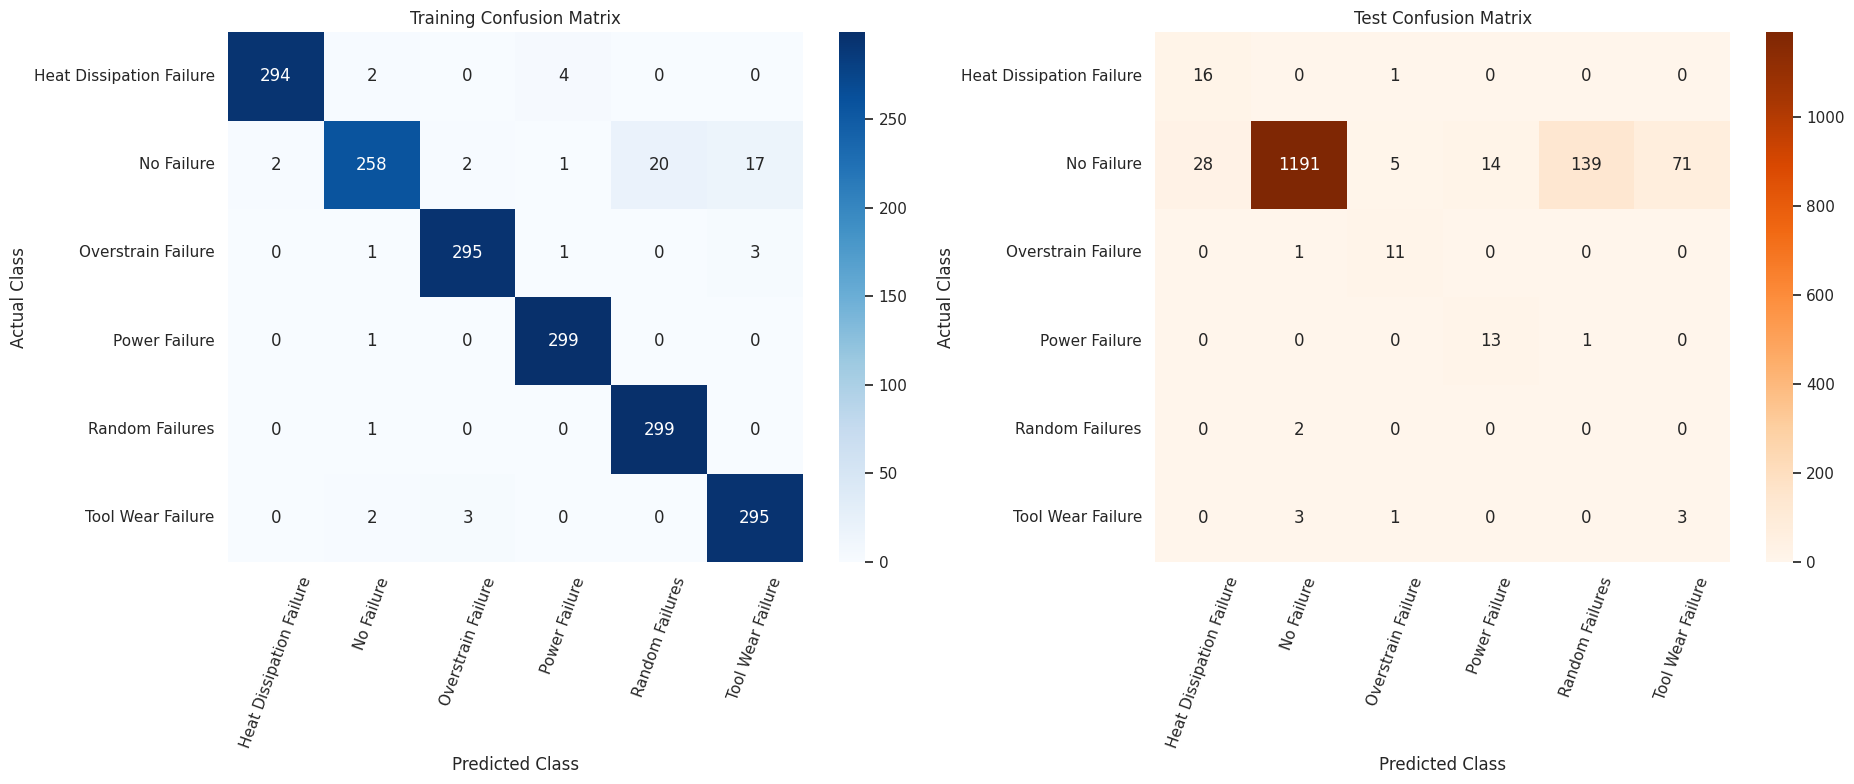

In [71]:

cm_train = confusion_matrix(
    y_train_true,
    y_train_pred,
    labels=np.arange(num_classes)
)

cm_test = confusion_matrix(
    y_test_true,
    y_test_pred,
    labels=np.arange(num_classes)
)

fig, axes = plt.subplots(1, 2, figsize=(19, 8))

sns.heatmap(
    cm_train,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_,
    ax=axes[0]
)

axes[0].set_title("Training Confusion Matrix")
axes[0].set_xlabel("Predicted Class")
axes[0].set_ylabel("Actual Class")

sns.heatmap(
    cm_test,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_,
    ax=axes[1]
)

axes[1].set_title("Test Confusion Matrix")
axes[1].set_xlabel("Predicted Class")
axes[1].set_ylabel("Actual Class")

for ax in axes:
    ax.tick_params(axis="x", rotation=70)
    ax.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()


<Figure size 1400x700 with 0 Axes>

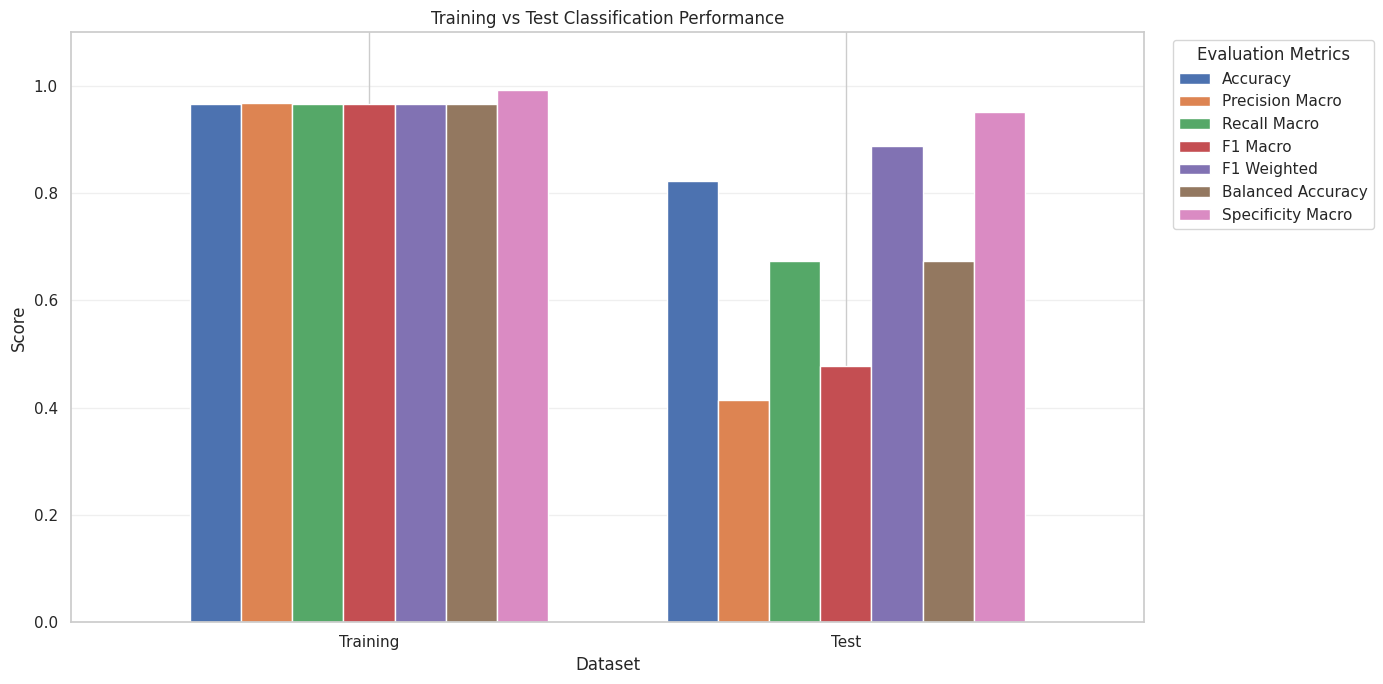

Evaluation Results Saved Successfully


In [72]:

metrics_plot = metrics_comparison.set_index("Dataset")

plt.figure(figsize=(14, 7))

metrics_plot.plot(
    kind="bar",
    figsize=(14, 7),
    rot=0,
    width=0.75
)

plt.title("Training vs Test Classification Performance")
plt.xlabel("Dataset")
plt.ylabel("Score")
plt.ylim(0, 1.1)
plt.legend(
    title="Evaluation Metrics",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

metrics_comparison.to_csv(
    "/kaggle/working/classification_evaluation_metrics.csv",
    index=False
)

per_class_results.to_csv(
    "/kaggle/working/classification_per_class_metrics.csv",
    index=False
)

print("Evaluation Results Saved Successfully")


In [73]:

import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn

from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

class RegularizedMaintenanceMLP(nn.Module):
    def __init__(self, input_size=8, num_classes=6, dropout=0.0):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        return self.network(x)

regularization_device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", regularization_device)
print("Input Features:", input_size_cls)
print("Output Classes:", num_classes)

sample_model = RegularizedMaintenanceMLP(
    input_size=input_size_cls,
    num_classes=num_classes,
    dropout=0.15
)

print(sample_model)


Device: cuda
Input Features: 8
Output Classes: 6
RegularizedMaintenanceMLP(
  (network): Sequential(
    (0): Linear(in_features=8, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.15, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.15, inplace=False)
    (6): Linear(in_features=64, out_features=6, bias=True)
  )
)


In [75]:

def train_cls_regularized(
    name,
    dropout=0.0,
    weight_decay=0.0,
    early_stopping=False
):
    torch.manual_seed(42)
    np.random.seed(42)

    net = RegularizedMaintenanceMLP(
        input_size=input_size_cls,
        num_classes=num_classes,
        dropout=dropout
    ).to(regularization_device)

    optimizer = torch.optim.Adam(
        net.parameters(),
        lr=0.001,
        weight_decay=weight_decay
    )

    criterion = nn.CrossEntropyLoss()

    generator = torch.Generator().manual_seed(42)

    loader = DataLoader(
        TensorDataset(
            X_cls_train_balanced_tensor,
            y_cls_train_balanced_tensor
        ),
        batch_size=128,
        shuffle=True,
        generator=generator
    )

    max_epochs = 100 if early_stopping else 60
    patience = 15
    waiting = 0

    best_f1 = -1.0
    best_epoch = 0
    best_state = None

    train_history = []
    val_history = []
    val_f1_history = []

    for epoch in range(max_epochs):
        net.train()

        total_loss = 0
        total_samples = 0

        for xb, yb in loader:
            xb = xb.to(regularization_device)
            yb = yb.to(regularization_device)

            optimizer.zero_grad()

            outputs = net(xb)
            loss = criterion(outputs, yb)

            loss.backward()
            optimizer.step()

            total_loss += loss.item() * xb.size(0)
            total_samples += xb.size(0)

        train_loss = total_loss / total_samples

        net.eval()

        with torch.no_grad():
            val_outputs = net(
                X_cls_val_tensor.to(regularization_device)
            )

            val_loss = criterion(
                val_outputs,
                y_cls_val_tensor.to(regularization_device)
            ).item()

            val_pred = torch.argmax(
                val_outputs, dim=1
            ).cpu().numpy()

        val_f1 = f1_score(
            y_cls_val_np,
            val_pred,
            average="macro",
            zero_division=0
        )

        train_history.append(train_loss)
        val_history.append(val_loss)
        val_f1_history.append(val_f1)

        if val_f1 > best_f1 + 1e-6:
            best_f1 = val_f1
            best_epoch = epoch + 1
            best_state = copy.deepcopy(net.state_dict())
            waiting = 0
        else:
            waiting += 1

        if early_stopping and waiting >= patience:
            break

    if early_stopping:
        net.load_state_dict(best_state)

    print(
        f"{name} | "
        f"Epochs: {len(train_history)} | "
        f"Best Epoch: {best_epoch} | "
        f"Best Val Macro F1: {best_f1:.4f}"
    )

    return {
        "name": name,
        "model": net,
        "train_loss": train_history,
        "val_loss": val_history,
        "val_f1": val_f1_history,
        "best_epoch": best_epoch,
        "epochs_completed": len(train_history)
    }


In [76]:

regularization_configs = [
    {
        "name": "Dropout",
        "dropout": 0.15,
        "weight_decay": 0.0,
        "early_stopping": False
    },
    {
        "name": "L2 Weight Decay",
        "dropout": 0.0,
        "weight_decay": 0.0001,
        "early_stopping": False
    },
    {
        "name": "Early Stopping",
        "dropout": 0.0,
        "weight_decay": 0.0,
        "early_stopping": True
    },
    {
        "name": "Dropout + L2 + Early Stopping",
        "dropout": 0.15,
        "weight_decay": 0.0001,
        "early_stopping": True
    }
]

cls_regularization_results = []

for config in regularization_configs:
    result = train_cls_regularized(**config)
    cls_regularization_results.append(result)

print("\nAll Regularization Experiments Completed")


Dropout | Epochs: 60 | Best Epoch: 58 | Best Val Macro F1: 0.4642
L2 Weight Decay | Epochs: 60 | Best Epoch: 51 | Best Val Macro F1: 0.4873
Early Stopping | Epochs: 77 | Best Epoch: 62 | Best Val Macro F1: 0.4868
Dropout + L2 + Early Stopping | Epochs: 47 | Best Epoch: 32 | Best Val Macro F1: 0.4486

All Regularization Experiments Completed


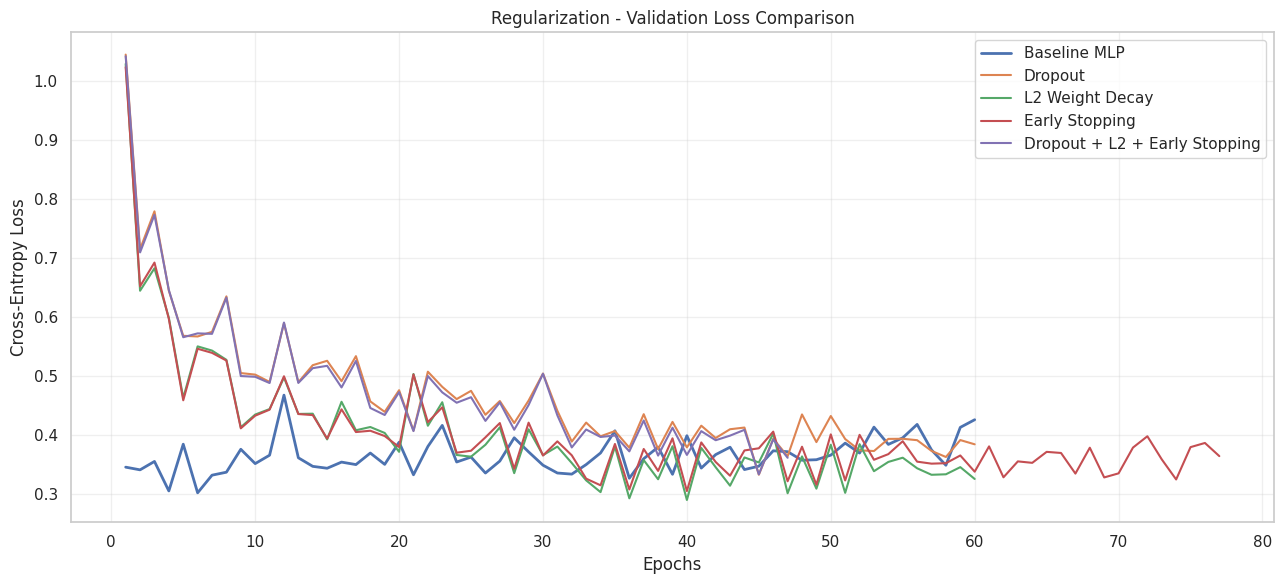

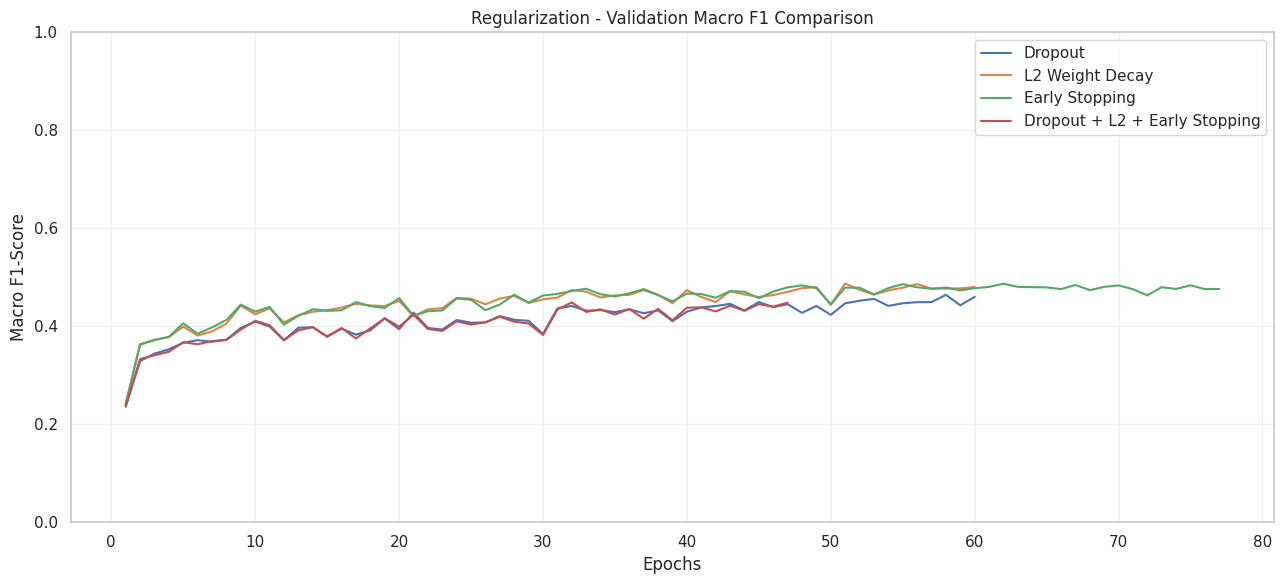

In [77]:

plt.figure(figsize=(13, 6))

plt.plot(
    range(1, len(cls_val_losses) + 1),
    cls_val_losses,
    label="Baseline MLP",
    linewidth=2
)

for result in cls_regularization_results:
    plt.plot(
        range(1, len(result["val_loss"]) + 1),
        result["val_loss"],
        label=result["name"]
    )

plt.title("Regularization - Validation Loss Comparison")
plt.xlabel("Epochs")
plt.ylabel("Cross-Entropy Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(13, 6))

for result in cls_regularization_results:
    plt.plot(
        range(1, len(result["val_f1"]) + 1),
        result["val_f1"],
        label=result["name"]
    )

plt.title("Regularization - Validation Macro F1 Comparison")
plt.xlabel("Epochs")
plt.ylabel("Macro F1-Score")
plt.ylim(0, 1)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Balanced Accuracy
0,Baseline MLP,0.9200,0.4312,0.5939,0.4895,0.5939
1,Early Stopping,0.9240,0.4321,0.5849,0.4868,0.5849
2,L2 Weight Decay,0.9120,0.4213,0.5925,0.4802,0.5925
3,Dropout,0.8813,0.3952,0.5990,0.4600,0.5990
4,Dropout + L2 + Early Stopping,0.8627,0.3816,0.6195,0.4486,0.6195
5,Optimized MLP,0.8273,0.3728,0.6361,0.4363,0.6361


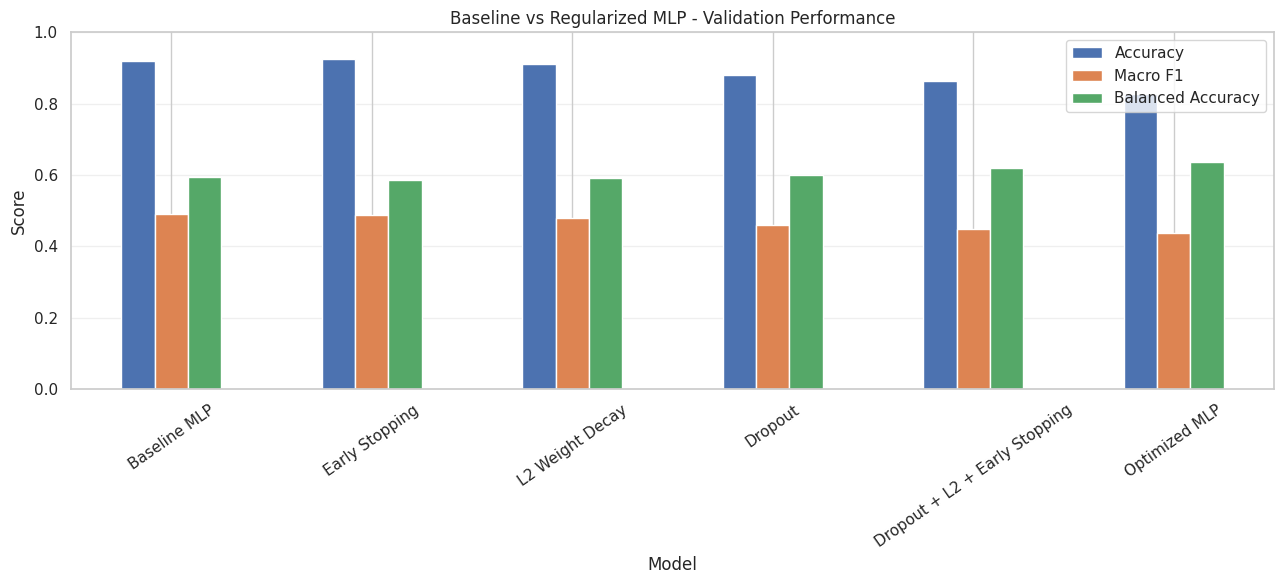

In [78]:

def predict_regularized_model(net, X_tensor):
    net.eval()

    with torch.no_grad():
        outputs = net(
            X_tensor.to(regularization_device)
        )

        predictions = torch.argmax(
            outputs, dim=1
        ).cpu().numpy()

    return predictions


def calculate_cls_metrics(name, y_true, y_pred):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro Precision": precision_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ),
        "Macro Recall": recall_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ),
        "Macro F1": f1_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            y_true, y_pred
        )
    }


baseline_val_pred = predict_regularized_model(
    cls_baseline_model,
    X_cls_val_tensor
)

optimized_val_pred = cls_optimized_model.predict(
    X_cls_val
)

validation_rows = [
    calculate_cls_metrics(
        "Baseline MLP",
        y_cls_val_np,
        baseline_val_pred
    ),
    calculate_cls_metrics(
        "Optimized MLP",
        y_cls_val_np,
        optimized_val_pred
    )
]

for result in cls_regularization_results:
    predictions = predict_regularized_model(
        result["model"],
        X_cls_val_tensor
    )

    result["val_predictions"] = predictions

    validation_rows.append(
        calculate_cls_metrics(
            result["name"],
            y_cls_val_np,
            predictions
        )
    )

cls_regularization_comparison = pd.DataFrame(
    validation_rows
)

cls_regularization_comparison = (
    cls_regularization_comparison
    .sort_values("Macro F1", ascending=False)
    .reset_index(drop=True)
)

display(cls_regularization_comparison.round(4))

cls_regularization_comparison.set_index("Model")[
    ["Accuracy", "Macro F1", "Balanced Accuracy"]
].plot(
    kind="bar",
    figsize=(13, 6),
    rot=35
)

plt.title("Baseline vs Regularized MLP - Validation Performance")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


Best Regularization Configuration:
Early Stopping

Best Overall Model on Validation:
Baseline MLP


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Balanced Accuracy
0,Baseline MLP,0.9200,0.4604,0.6640,0.5271,0.6640
1,Optimized MLP,0.8227,0.4153,0.6729,0.4778,0.6729
2,Early Stopping,0.9247,0.4681,0.6689,0.5348,0.6689


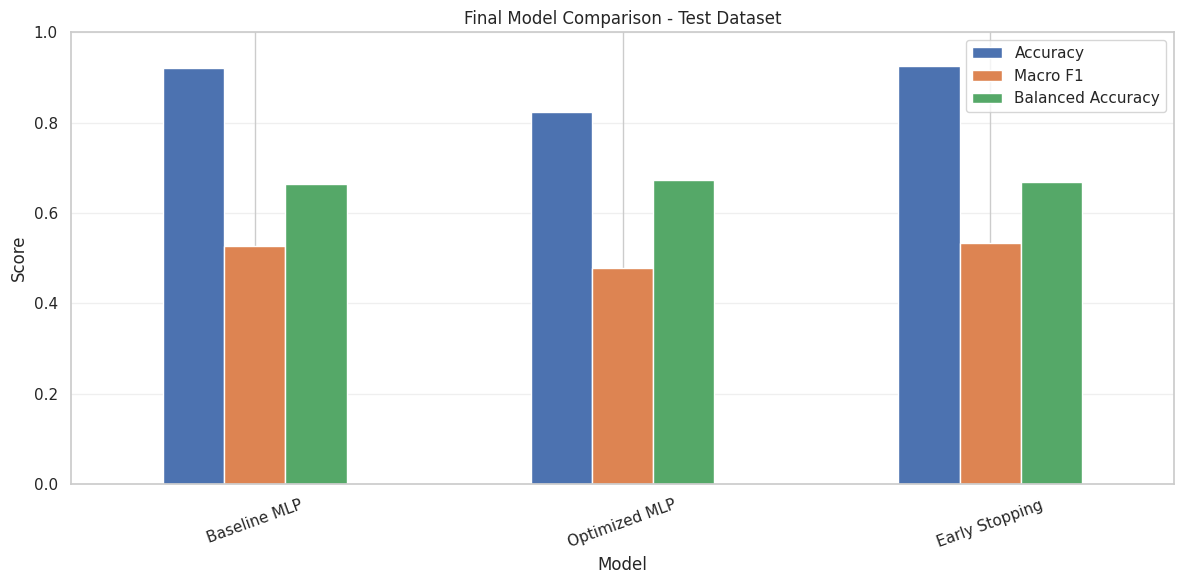

In [79]:

best_regularized_result = max(
    cls_regularization_results,
    key=lambda result: f1_score(
        y_cls_val_np,
        result["val_predictions"],
        average="macro",
        zero_division=0
    )
)

best_regularized_model = best_regularized_result["model"]

print("Best Regularization Configuration:")
print(best_regularized_result["name"])

print("\nBest Overall Model on Validation:")
print(cls_regularization_comparison.iloc[0]["Model"])

baseline_test_pred = predict_regularized_model(
    cls_baseline_model,
    X_cls_test_tensor
)

optimized_test_pred = cls_optimized_model.predict(
    X_cls_test
)

regularized_test_pred = predict_regularized_model(
    best_regularized_model,
    X_cls_test_tensor
)

final_test_rows = [
    calculate_cls_metrics(
        "Baseline MLP",
        y_cls_test_np,
        baseline_test_pred
    ),
    calculate_cls_metrics(
        "Optimized MLP",
        y_cls_test_np,
        optimized_test_pred
    ),
    calculate_cls_metrics(
        best_regularized_result["name"],
        y_cls_test_np,
        regularized_test_pred
    )
]

cls_final_comparison = pd.DataFrame(
    final_test_rows
)

display(cls_final_comparison.round(4))

cls_final_comparison.set_index("Model")[
    ["Accuracy", "Macro F1", "Balanced Accuracy"]
].plot(
    kind="bar",
    figsize=(12, 6),
    rot=20
)

plt.title("Final Model Comparison - Test Dataset")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


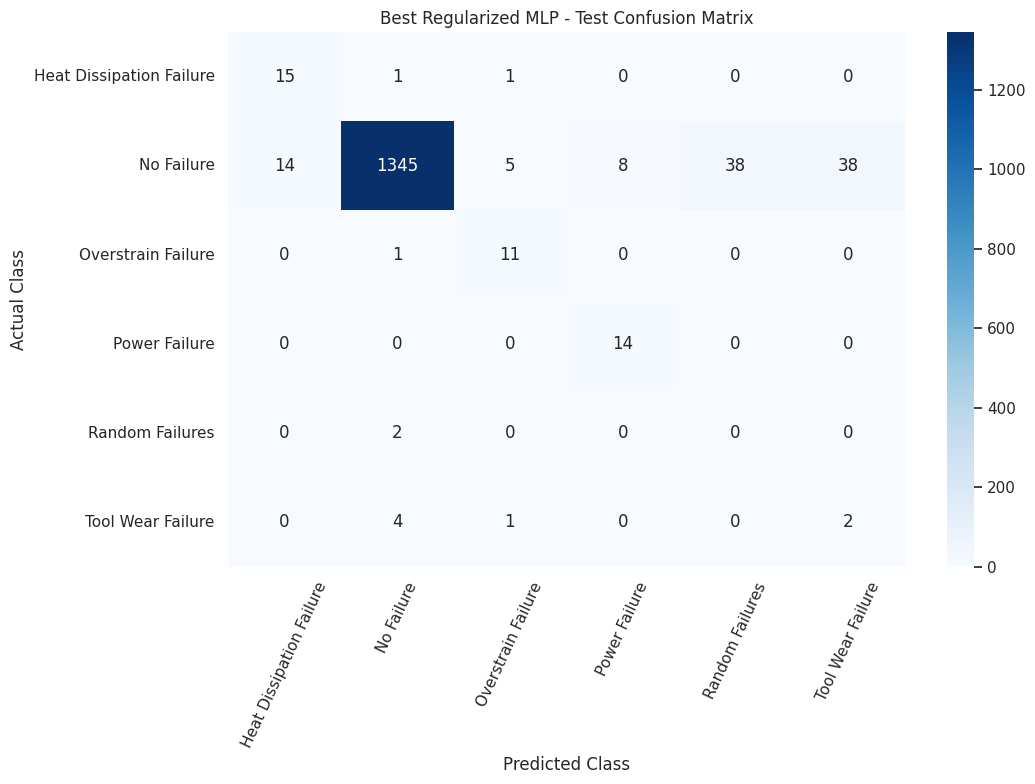

Best Regularized Model - Classification Report
                          precision    recall  f1-score   support

Heat Dissipation Failure     0.5172    0.8824    0.6522        17
              No Failure     0.9941    0.9289    0.9604      1448
      Overstrain Failure     0.6111    0.9167    0.7333        12
           Power Failure     0.6364    1.0000    0.7778        14
         Random Failures     0.0000    0.0000    0.0000         2
       Tool Wear Failure     0.0500    0.2857    0.0851         7

                accuracy                         0.9247      1500
               macro avg     0.4681    0.6689    0.5348      1500
            weighted avg     0.9765    0.9247    0.9480      1500

All Results Saved Successfully


In [80]:

cm_regularized = confusion_matrix(
    y_cls_test_np,
    regularized_test_pred,
    labels=np.arange(num_classes)
)

plt.figure(figsize=(11, 8))

sns.heatmap(
    cm_regularized,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Best Regularized MLP - Test Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=65)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

print("Best Regularized Model - Classification Report")

print(
    classification_report(
        y_cls_test_np,
        regularized_test_pred,
        labels=np.arange(num_classes),
        target_names=label_encoder.classes_,
        digits=4,
        zero_division=0
    )
)

cls_regularization_comparison.to_csv(
    "/kaggle/working/regularization_validation_comparison.csv",
    index=False
)

cls_final_comparison.to_csv(
    "/kaggle/working/regularization_final_test_comparison.csv",
    index=False
)

torch.save(
    {
        "model_state_dict": best_regularized_model.state_dict(),
        "model_name": best_regularized_result["name"],
        "input_size": input_size_cls,
        "num_classes": num_classes,
        "class_names": label_encoder.classes_.tolist(),
        "best_epoch": best_regularized_result["best_epoch"]
    },
    "/kaggle/working/maintenance_regularized_mlp.pth"
)

print("All Results Saved Successfully")
